# Recomendação de filmes com Neural Collaborative Filtering (MovieLens 100K)

**MAE5920 - Aprendizagem Profunda (2026)** · Docente: Hamed Yazdanpanah

Alan Kon (NUSP 4784830), Lucas Alves (NUSP 12693500) e Felipe Gimenez (NUSP 11916728)

Este notebook é o projeto inteiro. Ele lê os dados, separa treino, validação e teste no tempo, implementa e treina
os três modelos (popularidade, fatoração de matrizes e NeuMF), mede vazamento de informação, calibração, resíduos
por segmento e custo computacional, e faz todas as tabelas e figuras usadas no relatório e na apresentação. A
tabela de resultados é gravada em `3_tabela_de_resultados.xlsx`; as outras tabelas (CSV) e as figuras
(PNG) vão para a pasta `suporte/resultados/`, criada na execução. A calibração e o diagnóstico dos resíduos
estão nas seções 9 e 10, e o custo computacional, na seção 11.

**Como rodar.** Python 3.10 ou mais novo, com numpy, pandas, matplotlib, openpyxl e PyTorch (a versão para CPU
basta). Os dados do MovieLens 100K são baixados do site do GroupLens na primeira execução e ficam em `../ml-100k`,
fora da pasta de entrega, porque a licença não permite redistribuir os arquivos. Rodar tudo levou cerca de 38
minutos num computador pessoal (Intel Core i7-1165G7), numa thread só. Com `RAPIDO = True` roda uma versão curta,
só para conferir que tudo funciona (as tabelas e figuras dela vão para `suporte/resultados_rapido/`).

In [1]:
# o torch vem primeiro: em algumas instalacoes do Windows, importar o matplotlib antes quebra o carregamento
# das DLLs do torch (erro WinError 1114)
import torch
import torch.nn.functional as F

import os
import time
import zipfile
import warnings
import platform
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter
from IPython.display import display

RAPIDO = False   # True: grade minima e 3 epocas, so pra testar se tudo roda

# os dados ficam fora da pasta de entrega (a licenca do MovieLens nao deixa redistribuir)
PASTA_DADOS = os.environ.get("ML100K", os.path.join("..", "ml-100k"))
# o teste rapido grava numa pasta separada, pra nao apagar as tabelas da execucao completa
SAIDA = os.path.join("suporte", "resultados_rapido" if RAPIDO else "resultados")
PASTA_FIG = os.path.join(SAIDA, "figuras")
os.makedirs(PASTA_FIG, exist_ok=True)
# a tabela do item 3 fica na pasta da entrega (no teste rapido, junto com as outras tabelas)
EXCEL = os.path.join(SAIDA if RAPIDO else ".", "3_tabela_de_resultados.xlsx")

K = 10              # tamanho da lista recomendada
LOTE = 256          # exemplos por passo do Adam
MAX_EPOCAS = 60
PACIENCIA = 8       # o treino para depois de 8 epocas sem melhorar o NDCG@10 de validacao
NEG_INICIAL = 4     # negativos por positivo na primeira rodada da busca
SEMENTE_BUSCA = 0
SEMENTES = [1, 2, 3, 4, 5]          # treinos finais de cada modelo
SEMENTES_EMBARALHADO = [1, 2, 3]    # repeticoes do split com a ordem embaralhada
SEMENTE_CALIBRACAO = 2024           # so pra sortear os pares da calibracao
N_BOOT = 1000                       # reamostragens nos intervalos de confianca

# grade da busca de hiperparametros (secao 5)
DIMS = [8, 16, 32, 64]
LRS = [0.001, 0.005]
NEGS = [1, 8]                       # testados depois do NEG_INICIAL
WDS = [1e-6, 1e-5, 1e-4]
LRS_NEUMF = [1e-5, 1e-4, 1e-3]

FAIXAS_IDADE = [0, 24, 34, 44, 54, 200]
NOMES_IDADE = ["até 24", "25-34", "35-44", "45-54", "55+"]

if RAPIDO:
    MAX_EPOCAS, SEMENTES, SEMENTES_EMBARALHADO, N_BOOT = 3, [1, 2], [1], 200
    DIMS, LRS, NEGS, WDS, LRS_NEUMF = [16], [0.005], [8], [1e-5], [1e-4]

# uma thread so: assim o resultado nao depende de quantos nucleos a maquina tem
torch.set_num_threads(1)
# com Adam e weight decay alguns pesos ficam minusculos (numeros "subnormais") e deixam a CPU bem mais lenta;
# isso arredonda esses valores pra zero, sem efeito pratico no modelo
torch.set_flush_denormal(True)
# efeito colateral da linha de cima: o numpy reclama que o menor subnormal virou zero. Pode ignorar
warnings.filterwarnings("ignore", message="The value of the smallest subnormal")

pd.set_option("display.precision", 4)
pd.set_option("display.width", 150)

# cores e estilo dos graficos (as mesmas figuras vao para o relatorio e para os slides)
AZUL, LARANJA, CINZA, CINZA_CLARO = "#0d2b52", "#eb6834", "#9b9a94", "#c9c7bf"
TINTA, TINTA2 = "#1a1a1a", "#52514e"
CORES = {"pop": CINZA, "mf": AZUL, "neumf": LARANJA}
NOMES = {"pop": "Popularidade", "mf": "MF", "neumf": "NeuMF"}
# Calibri e a fonte dos slides; se a maquina nao tiver, fica a padrao do matplotlib
FONTE = "Calibri" if "Calibri" in {f.name for f in font_manager.fontManager.ttflist} else "DejaVu Sans"
plt.rcParams.update({"font.family": FONTE, "font.size": 11, "axes.titlesize": 11, "axes.titlelocation": "left",
                     "axes.labelcolor": TINTA2, "axes.edgecolor": CINZA_CLARO, "xtick.color": TINTA2,
                     "ytick.color": TINTA2, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#ebeae6", "axes.axisbelow": True,
                     "legend.frameon": False, "figure.dpi": 110})


def salva(tabela, nome):
    tabela.to_csv(os.path.join(SAIDA, nome + ".csv"), index=False)


def mostra(fig, nome):
    # grava a figura em PNG (e a que vai para o relatorio e os slides) e mostra aqui
    fig.savefig(os.path.join(PASTA_FIG, nome + ".png"), dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()


def br(x, casas=3):
    # numero com virgula decimal, para escrever dentro dos graficos
    return ("%.*f" % (casas, x)).replace(".", ",").replace("-", "−")


def sinal(x, casas=1):
    return ("+" if x >= 0 else "−") + br(abs(x), casas)


def virgula(ax, eixo="both"):
    # eixos com virgula decimal
    formato = FuncFormatter(lambda v, pos: ("%g" % v).replace(".", ",").replace("-", "−"))
    if eixo in ("x", "both"):
        ax.xaxis.set_major_formatter(formato)
    if eixo in ("y", "both"):
        ax.yaxis.set_major_formatter(formato)


t_inicio = time.time()

## 1. Dados

O MovieLens 100K (Harper & Konstan, 2015) tem 100 mil avaliações de 943 usuários sobre 1.682 filmes, coletadas
entre setembro de 1997 e abril de 1998. Usamos quatro arquivos: `u.data` (quem avaliou o quê, com nota e horário),
`u.item` (título, data de lançamento e gêneros do filme), `u.user` (idade, sexo, ocupação e CEP) e `u.genre`
(só os nomes das 19 colunas de gênero).

In [2]:
if not os.path.exists(os.path.join(PASTA_DADOS, "u.data")):
    pasta_mae = os.path.dirname(os.path.abspath(PASTA_DADOS))
    os.makedirs(pasta_mae, exist_ok=True)
    arquivo_zip = os.path.join(pasta_mae, "ml-100k.zip")
    print("baixando o MovieLens 100K do site do GroupLens...")
    urllib.request.urlretrieve("https://files.grouplens.org/datasets/movielens/ml-100k.zip", arquivo_zip)
    with zipfile.ZipFile(arquivo_zip) as z:
        z.extractall(pasta_mae)
    PASTA_DADOS = os.path.join(pasta_mae, "ml-100k")   # o zip sempre cria a pasta ml-100k

notas = pd.read_csv(os.path.join(PASTA_DADOS, "u.data"), sep="\t", names=["user_id", "item_id", "rating", "ts"])
generos = pd.read_csv(os.path.join(PASTA_DADOS, "u.genre"), sep="|", names=["genero", "idx"]).dropna()
generos = generos.genero.tolist()
filmes = pd.read_csv(os.path.join(PASTA_DADOS, "u.item"), sep="|", encoding="latin-1",
                     names=["item_id", "title", "release_date", "video_release_date", "imdb_url"] + generos)
usuarios = pd.read_csv(os.path.join(PASTA_DADOS, "u.user"), sep="|",
                       names=["user_id", "age", "gender", "occupation", "zip"], dtype={"zip": str})

# no arquivo os ids comecam em 1; aqui viram indices de 0 a n-1, que e o que o numpy e o torch usam
notas["u"] = notas.user_id - 1
notas["i"] = notas.item_id - 1
NU, NI = len(usuarios), len(filmes)
print(NU, "usuários,", NI, "filmes,", len(notas), "avaliações")

943 usuários, 1682 filmes, 100000 avaliações


### Dicionário de dados (resumo)

In [3]:
def pct_faltante(coluna):
    return round(100 * coluna.isna().mean(), 2)


filmes["lancamento"] = pd.to_datetime(filmes.release_date, format="%d-%b-%Y", errors="coerce")
data_inicio = pd.to_datetime(notas.ts.min(), unit="s")
data_fim = pd.to_datetime(notas.ts.max(), unit="s")
cep_fora = (~usuarios.zip.str.fullmatch(r"\d{5}")).sum()   # CEPs que nao sao 5 digitos (ex.: canadenses)
n_generos = filmes[generos].sum(axis=1)
periodo_lanc = "%s a %s" % (filmes.lancamento.min().date(), filmes.lancamento.max().date())

linhas = [
    ["u.data", "user_id", "inteiro (id)", "1 a %d" % notas.user_id.max(), "usuário que avaliou",
     pct_faltante(notas.user_id)],
    ["u.data", "item_id", "inteiro (id)", "1 a %d" % notas.item_id.max(), "filme avaliado",
     pct_faltante(notas.item_id)],
    ["u.data", "rating", "inteiro ordinal", "1 a 5", "nota em estrelas", pct_faltante(notas.rating)],
    ["u.data", "timestamp", "inteiro (segundos)", "%s a %s" % (data_inicio.date(), data_fim.date()),
     "momento da avaliação", pct_faltante(notas.ts)],
    ["u.user", "user_id", "inteiro (id)", "1 a %d" % usuarios.user_id.max(), "chave do usuário",
     pct_faltante(usuarios.user_id)],
    ["u.user", "age", "inteiro", "%d a %d" % (usuarios.age.min(), usuarios.age.max()), "idade declarada",
     pct_faltante(usuarios.age)],
    ["u.user", "gender", "categórico", "M ou F", "sexo declarado", pct_faltante(usuarios.gender)],
    ["u.user", "occupation", "categórico", "%d categorias" % usuarios.occupation.nunique(), "ocupação",
     pct_faltante(usuarios.occupation)],
    ["u.user", "zip_code", "texto", "%d valores, %d fora do padrão de 5 dígitos" % (usuarios.zip.nunique(), cep_fora),
     "CEP", pct_faltante(usuarios.zip)],
    ["u.item", "item_id", "inteiro (id)", "1 a %d" % filmes.item_id.max(), "chave do filme",
     pct_faltante(filmes.item_id)],
    ["u.item", "title", "texto", "%d títulos distintos" % filmes.title.nunique(), "título com o ano",
     pct_faltante(filmes.title)],
    ["u.item", "release_date", "data", periodo_lanc, "data de lançamento", pct_faltante(filmes.release_date)],
    ["u.item", "video_release_date", "data", "sempre vazia", "lançamento em vídeo",
     pct_faltante(filmes.video_release_date)],
    ["u.item", "imdb_url", "texto", "endereço web", "página do filme no IMDb", pct_faltante(filmes.imdb_url)],
    ["u.item", "%d colunas de gênero" % len(generos), "binário (0/1)", "%s, ..., %s" % (generos[0], generos[-1]),
     "um filme pode ter vários (média de %.2f, máximo de %d)" % (n_generos.mean(), n_generos.max()), 0.0],
]
dicionario = pd.DataFrame(linhas, columns=["arquivo", "variavel", "tipo", "dominio", "descricao", "pct_faltante"])
salva(dicionario, "dicionario")
dicionario

,arquivo,variavel,tipo,dominio,descricao,pct_faltante
0,u.data,user_id,inteiro (id),1 a 943,usuário que avaliou,0.00
1,u.data,item_id,inteiro (id),1 a 1682,filme avaliado,0.00
2,u.data,rating,inteiro ordinal,1 a 5,nota em estrelas,0.00
3,u.data,timestamp,inteiro (segundos),1997-09-20 a 1998-04-22,momento da avaliação,0.00
4,u.user,user_id,inteiro (id),1 a 943,chave do usuário,0.00
5,u.user,age,inteiro,7 a 73,idade declarada,0.00
6,u.user,gender,categórico,M ou F,sexo declarado,0.00
7,u.user,occupation,categórico,21 categorias,ocupação,0.00
8,u.user,zip_code,texto,"795 valores, 18 fora do padrão de 5 dígitos",CEP,0.00
9,u.item,item_id,inteiro (id),1 a 1682,chave do filme,0.00


In [4]:
por_usuario = notas.groupby("u").size()
por_filme = notas.groupby("i").size()
# minutos entre a primeira e a ultima avaliacao de cada usuario
duracao = notas.groupby("u").ts.agg(lambda t: (t.max() - t.min()) / 60)
mais_vistos = por_filme.sort_values(ascending=False).iloc[:int(np.ceil(0.1 * len(por_filme)))]

resumo = {
    "usuarios": NU, "filmes": NI, "avaliacoes": len(notas),
    "esparsidade_pct": 100 * (1 - len(notas) / (NU * NI)),
    "aval_usuario_min": por_usuario.min(), "aval_usuario_q1": por_usuario.quantile(0.25),
    "aval_usuario_mediana": por_usuario.median(), "aval_usuario_media": por_usuario.mean(),
    "aval_usuario_q3": por_usuario.quantile(0.75), "aval_usuario_max": por_usuario.max(),
    "aval_filme_min": por_filme.min(), "aval_filme_q1": por_filme.quantile(0.25),
    "aval_filme_mediana": por_filme.median(), "aval_filme_media": por_filme.mean(),
    "aval_filme_q3": por_filme.quantile(0.75), "aval_filme_max": por_filme.max(),
    "filmes_com_1_avaliacao": int((por_filme == 1).sum()), "filmes_com_menos_de_5": int((por_filme < 5).sum()),
    "filmes_10pct_mais_vistos": len(mais_vistos),
    "pct_avaliacoes_10pct_mais_vistos": 100 * mais_vistos.sum() / len(notas),
    "nota_media": notas.rating.mean(), "inicio": str(data_inicio.date()), "fim": str(data_fim.date()),
    "duracao_mediana_min": duracao.median(), "pct_usuarios_tudo_em_1_dia": 100 * (duracao < 24 * 60).mean(),
    "homens": int((usuarios.gender == "M").sum()), "mulheres": int((usuarios.gender == "F").sum()),
    "idade_mediana": usuarios.age.median(),
}
salva(pd.DataFrame({"medida": list(resumo), "valor": list(resumo.values())}), "dados_resumo")
# contagens por filme e por usuario (as mesmas dos graficos abaixo)
salva(por_filme.rename_axis("i").reset_index(name="avaliacoes"), "dados_por_filme")
salva(por_usuario.rename_axis("u").reset_index(name="avaliacoes"), "dados_por_usuario")

dist_notas = notas.rating.value_counts().sort_index().rename_axis("nota").reset_index(name="avaliacoes")
dist_notas["pct"] = 100 * dist_notas.avaliacoes / len(notas)
salva(dist_notas, "dados_notas")

faixa = pd.cut(usuarios.age, FAIXAS_IDADE, labels=NOMES_IDADE)
salva(faixa.value_counts().sort_index().rename_axis("faixa").reset_index(name="usuarios"), "dados_idade")
salva(usuarios.occupation.value_counts().rename_axis("ocupacao").reset_index(name="usuarios"), "dados_ocupacao")

# por genero: quantos filmes e que parte das avaliacoes (um filme conta em todos os seus generos)
gen_aval = filmes.set_index("item_id").loc[notas.item_id, generos]
tab_generos = pd.DataFrame({"genero": generos, "filmes": filmes[generos].sum().values,
                            "pct_avaliacoes": 100 * gen_aval.mean().values})
tab_generos = tab_generos.sort_values("filmes", ascending=False).reset_index(drop=True)
salva(tab_generos, "dados_generos")
pd.Series(resumo)

usuarios                                   943
filmes                                    1682
avaliacoes                              100000
esparsidade_pct                        93.6953
aval_usuario_min                            20
aval_usuario_q1                           33.0
aval_usuario_mediana                      65.0
aval_usuario_media                    106.0445
aval_usuario_q3                          148.0
aval_usuario_max                           737
aval_filme_min                               1
aval_filme_q1                              6.0
aval_filme_mediana                        27.0
aval_filme_media                        59.453
aval_filme_q3                             80.0
aval_filme_max                             583
filmes_com_1_avaliacao                     141
filmes_com_menos_de_5                      333
filmes_10pct_mais_vistos                   169
pct_avaliacoes_10pct_mais_vistos        42.871
nota_media                              3.5299
inicio       

In [5]:
# notas: a media e quanto das avaliacoes e 4 ou 5 (argumento para deixar a nota de fora, mais abaixo)
print("nota média: %.2f | notas 4 ou 5: %.0f%% das avaliações"
      % (notas.rating.mean(), dist_notas[dist_notas.nota >= 4].pct.sum()))
display(dist_notas)
# generos: numero de filmes e % das avaliacoes (um filme pode ter varios generos, entao a soma passa de 100%)
tab_generos

nota média: 3.53 | notas 4 ou 5: 55% das avaliações


,nota,avaliacoes,pct
0,1,6110,6.110
1,2,11370,11.370
2,3,27145,27.145
3,4,34174,34.174
4,5,21201,21.201


,genero,filmes,pct_avaliacoes
0,Drama,725,39.895
1,Comedy,505,29.832
2,Action,251,25.589
3,Thriller,251,21.872
4,Romance,247,19.461
5,Adventure,135,13.753
6,Children's,122,7.182
7,Crime,109,8.055
8,Sci-Fi,101,12.730
9,Horror,92,5.317


### Problemas de qualidade

In [6]:
duplicados = filmes[filmes.title.duplicated(keep=False)]
seg_lancamento = (filmes.lancamento - pd.Timestamp("1970-01-01")).dt.total_seconds().values
antes_lancamento = notas.ts.values < seg_lancamento[notas.i.values]   # data faltante vira NaN e da False
empatado = notas.duplicated(["u", "ts"], keep=False)                  # mesma pessoa, mesmo segundo

qualidade = pd.DataFrame([
    ["duplicados", "títulos que aparecem com dois item_id", duplicados.title.nunique()],
    ["unknown", "filmes com título 'unknown'", int((filmes.title == "unknown").sum())],
    ["sem_data", "filmes sem data de lançamento", int(filmes.lancamento.isna().sum())],
    ["lancamento_1_jan", "filmes com lançamento em 1º de janeiro (data aproximada)",
     int(((filmes.lancamento.dt.day == 1) & (filmes.lancamento.dt.month == 1)).sum())],
    ["sem_imdb", "filmes sem link do IMDb", int(filmes.imdb_url.isna().sum())],
    ["video", "video_release_date preenchida", int(filmes.video_release_date.notna().sum())],
    ["antes_lancamento", "avaliações anteriores à data de lançamento", int(antes_lancamento.sum())],
    ["filmes_antes_lancamento", "filmes com avaliação anterior ao lançamento", notas.i[antes_lancamento].nunique()],
    ["pct_empatadas", "% de avaliações no mesmo segundo que outra do mesmo usuário", round(100 * empatado.mean(), 1)],
    ["duracao_mediana", "mediana de minutos entre a 1a e a última avaliação do usuário", round(duracao.median(), 1)],
    ["pct_1_dia", "% de usuários que avaliaram tudo em menos de 1 dia", round(100 * (duracao < 24 * 60).mean(), 1)],
], columns=["id", "checagem", "valor"], dtype=object)
salva(qualidade, "dados_qualidade")
print("exemplo de duplicado:", duplicados.sort_values("title")[["item_id", "title"]].head(2).values.tolist())
qualidade

exemplo de duplicado: [[670, 'Body Snatchers (1993)'], [573, 'Body Snatchers (1993)']]


,id,checagem,valor
0,duplicados,títulos que aparecem com dois item_id,18
1,unknown,filmes com título 'unknown',1
2,sem_data,filmes sem data de lançamento,1
3,lancamento_1_jan,filmes com lançamento em 1º de janeiro (data a...,1097
4,sem_imdb,filmes sem link do IMDb,3
5,video,video_release_date preenchida,0
6,antes_lancamento,avaliações anteriores à data de lançamento,231
7,filmes_antes_lancamento,filmes com avaliação anterior ao lançamento,24
8,pct_empatadas,% de avaliações no mesmo segundo que outra do ...,75.8
9,duracao_mediana,mediana de minutos entre a 1a e a última avali...,49.4


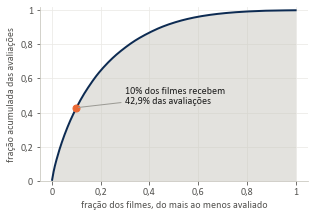

In [7]:
# cauda longa: fracao acumulada das avaliacoes contra a fracao dos filmes (do mais visto pro menos visto)
acum = np.cumsum(np.sort(por_filme.values)[::-1]) / len(notas)
x = np.arange(1, len(acum) + 1) / len(acum)
j = len(mais_vistos) - 1     # ultimo filme dos 10% mais vistos
fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.fill_between(x, acum, color=CINZA_CLARO, alpha=0.5, lw=0)
ax.plot(x, acum, color=AZUL, lw=2)
ax.plot(x[j], acum[j], "o", color=LARANJA, ms=7)
ax.annotate("10%% dos filmes recebem\n%s%% das avaliações" % br(100 * acum[j], 1), (x[j], acum[j]),
            xytext=(0.3, 0.45), color=TINTA, arrowprops=dict(arrowstyle="-", color=CINZA))
ax.set_xlabel("fração dos filmes, do mais ao menos avaliado")
ax.set_ylabel("fração acumulada das avaliações")
ax.set_ylim(0, 1.02)
virgula(ax)
mostra(fig, "dados_concentracao")

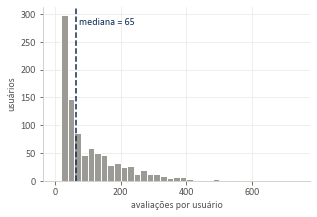

In [8]:
# quantas avaliacoes cada usuario tem (todos tem pelo menos 20)
fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.hist(por_usuario.values, bins=np.arange(0, por_usuario.max() + 20, 20), color=CINZA, edgecolor="white")
mediana = por_usuario.median()
ax.axvline(mediana, color=AZUL, lw=1.5, ls="--")
ax.text(mediana + 10, ax.get_ylim()[1] * 0.9, "mediana = %d" % mediana, color=AZUL)
ax.set_xlabel("avaliações por usuário")
ax.set_ylabel("usuários")
mostra(fig, "dados_usuarios")

**Feedback implícito, sem usar a nota.** Cada avaliação vira só "o usuário viu o filme" (1). A nota fica de fora
por dois motivos. Primeiro, a tarefa é ranquear filmes que o usuário **ainda não viu**, e a nota só existe para os
filmes vistos: não há nota nenhuma no conjunto que realmente importa. Segundo, as notas observadas são enviesadas
(viés de seleção): as pessoas escolhem ver filmes de que esperam gostar, então as notas que aparecem nos dados são
mais altas do que seriam se cada um visse um filme qualquer (a nota média aqui é 3,53, e 55% das avaliações são 4
ou 5). O que dá para aprender com segurança é **o que** cada pessoa escolhe ver.

## 2. Split temporal por usuário

Para cada usuário, as avaliações são ordenadas no tempo (empates no mesmo segundo são desfeitos pelo `item_id`).
Os primeiros 70% vão para treino, os 10% seguintes para validação e os últimos 20% para teste. Assim o modelo
sempre prevê o futuro de cada pessoa a partir do passado dela. Só dá para recomendar filmes que aparecem no
treino; filmes que surgem só na validação ou no teste (*cold-start*) saem do conjunto relevante.

In [9]:
def monta(tabela):
    # transforma a tabela (u, i, conjunto) em matrizes booleanas usuario x filme
    M = {}
    for c in ["treino", "val", "teste"]:
        m = np.zeros((NU, NI), dtype=bool)
        x = tabela[tabela.conjunto == c]
        m[x.u.values, x.i.values] = True
        M[c] = m
    cand = M["treino"].any(axis=0)   # filmes que podem ser recomendados (aparecem no treino)
    # "val" e "teste": so os filmes que existem no treino, que sao os relevantes de verdade.
    # "val_todos" e "teste_todos": tudo, inclusive cold-start (servem pra tirar do ranking o que ja foi visto)
    return {"tabela": tabela, "treino": M["treino"], "val_todos": M["val"], "teste_todos": M["teste"],
            "val": M["val"] & cand, "teste": M["teste"] & cand, "cand": cand}


def separa(notas, embaralhado=False, semente=0):
    d = notas.copy()
    if embaralhado:
        # mesma divisao 70/10/20 por usuario, mas numa ordem aleatoria (experimento de vazamento, secao 8)
        d["chave"] = np.random.default_rng(semente).random(len(d))
        d = d.sort_values(["u", "chave"])
    else:
        d = d.sort_values(["u", "ts", "i"])
    d = d.reset_index(drop=True)
    pos = d.groupby("u").cumcount().values             # posicao de cada avaliacao dentro do usuario
    n = d.groupby("u")["u"].transform("size").values    # total de avaliacoes do usuario
    # o 1e-9 evita erro de ponto flutuante (0.7 * 90 da 62.99999...)
    corte1 = np.floor(0.7 * n + 1e-9)
    corte2 = np.floor(0.8 * n + 1e-9)
    d["conjunto"] = np.where(pos < corte1, "treino", np.where(pos < corte2, "val", "teste"))
    return monta(d)


dados = separa(notas)
tab = dados["tabela"]
cand_idx = np.flatnonzero(dados["cand"])   # indices dos filmes do catalogo
tamanhos = tab.groupby("conjunto").agg(interacoes=("u", "size"), usuarios=("u", "nunique"), filmes=("i", "nunique"))
tamanhos = tamanhos.loc[["treino", "val", "teste"]].reset_index()
tamanhos["pct"] = 100 * tamanhos.interacoes / len(tab)
salva(tamanhos, "split_tamanhos")

cold = {"filmes_fora_do_treino": int((~dados["cand"]).sum())}
for c in ["val", "teste"]:
    fora = dados[c + "_todos"] & ~dados["cand"][None, :]
    cold[c + "_interacoes_cold"] = int(fora.sum())
    cold[c + "_filmes_cold"] = int(fora.any(axis=0).sum())
    cold[c + "_pct_cold"] = round(100 * fora.sum() / dados[c + "_todos"].sum(), 2)
    cold[c + "_usuarios_sem_relevante"] = int((dados[c].sum(axis=1) == 0).sum())
salva(pd.DataFrame({"medida": list(cold), "valor": list(cold.values())}), "split_cold_start")
display(pd.Series(cold, dtype=object))
tamanhos

filmes_fora_do_treino           108
val_interacoes_cold              40
val_filmes_cold                  37
val_pct_cold                    0.4
val_usuarios_sem_relevante        0
teste_interacoes_cold           122
teste_filmes_cold                88
teste_pct_cold                  0.6
teste_usuarios_sem_relevante      0
dtype: object

,conjunto,interacoes,usuarios,filmes,pct
0,treino,69575,943,1574,69.575
1,val,10044,943,1277,10.044
2,teste,20381,943,1508,20.381


## 3. Métricas

Para cada usuário ranqueamos **todos** os filmes candidatos que ele ainda não viu (na validação tiramos os do
treino; no teste, os do treino e os da validação) e olhamos a lista dos 10 primeiros. Com $R_u$ = filmes
relevantes do usuário no conjunto avaliado e $\mathrm{rel}_j = 1$ se o filme na posição $j$ é relevante:

- **Recall@10** $= \frac{\text{acertos no top-10}}{\min(|R_u|, 10)}$: que parte do que dava para acertar foi
  acertada. Dividimos por $\min(|R_u|,10)$ porque uma lista de 10 não acerta mais que 10.
- **NDCG@10** $= \frac{\sum_{j=1}^{10} \mathrm{rel}_j / \log_2(j+1)}{\text{o mesmo valor na lista ideal}}$: como o
  recall, mas um acerto vale mais quanto mais alto ele aparece. Vai de 0 a 1.
- **MRR** $= \frac{1}{|U|} \sum_{u \in U} \frac{1}{\mathrm{pos}_u}$, em que $U$ é o conjunto dos usuários
  avaliados e $\mathrm{pos}_u$ é a posição do primeiro filme relevante do usuário $u$ no ranking completo (sem
  cortar em 10): a média, entre os usuários, de quão cedo vem o primeiro acerto.
- **Coverage@10**: fração dos 1.682 filmes que aparecem em pelo menos uma lista; mostra se o modelo recomenda
  sempre os mesmos filmes.

Recall e NDCG também são calculados para cada usuário e depois promediados entre os usuários de $U$, como o MRR
(todos têm pelo menos um relevante na validação e no teste); a cobertura é contada sobre todas as listas juntas.
Empates de escore são desfeitos pelo menor `item_id`. Na linha "treino" das tabelas
medimos o quanto o modelo reconstrói os próprios filmes de treino: nenhum filme visto é excluído, só saem os que
estão fora do catálogo.

In [10]:
def proibidos(dados, conjunto):
    # o que nao pode entrar no ranking de cada usuario. [None, :] vira uma linha (1 x filmes) que o numpy
    # repete pra cada usuario
    fora = ~dados["cand"][None, :]
    if conjunto == "treino":
        return np.broadcast_to(fora, (NU, NI))
    if conjunto == "val":
        return dados["treino"] | fora
    return dados["treino"] | dados["val_todos"] | fora


def avalia(S, dados, conjunto):
    # S: escores (usuarios x filmes). Devolve as metricas de cada usuario (nan pra quem nao tem relevante)
    rel = dados[conjunto]
    proib = proibidos(dados, conjunto)
    # ordena do maior escore pro menor: os proibidos viram -inf e, com o sinal trocado, vao pro fim;
    # o argsort estavel deixa o menor item_id na frente quando empata
    ordem = np.argsort(-np.where(proib, -np.inf, S), axis=1, kind="stable")
    top = ordem[:, :K]
    acerto = np.take_along_axis(rel, top, axis=1)        # usuarios x 10, True onde acertou
    n_rel = rel.sum(axis=1)
    tem = n_rel > 0
    desconto = 1 / np.log2(np.arange(2, K + 2))           # 1/log2(posicao + 1)
    dcg = (acerto * desconto).sum(axis=1)
    # lista ideal: os min(|R|, 10) relevantes no topo. soma_descontos[n] = soma dos n primeiros descontos
    soma_descontos = np.concatenate([[0], np.cumsum(desconto)])
    idcg = soma_descontos[np.minimum(n_rel, K)]
    ndcg = np.where(tem, dcg / np.maximum(idcg, 1e-12), np.nan)
    recall = np.where(tem, acerto.sum(axis=1) / np.maximum(np.minimum(n_rel, K), 1), np.nan)
    # MRR no ranking inteiro: o argmax de um vetor True/False da a posicao do primeiro True. Usar a mesma
    # ordem do top-10 garante o mesmo desempate
    primeiro = np.argmax(np.take_along_axis(rel, ordem, axis=1), axis=1) + 1
    mrr = np.where(tem, 1 / primeiro, np.nan)
    cobertura = len(np.unique(top[tem])) / NI
    return {"ndcg": ndcg, "recall": recall, "mrr": mrr, "cobertura": cobertura, "top": top}


def medias(m):
    return {"ndcg": np.nanmean(m["ndcg"]), "recall": np.nanmean(m["recall"]), "mrr": np.nanmean(m["mrr"]),
            "cobertura": m["cobertura"]}


def escores_pop(matriz):
    # popularidade: todo usuario recebe o mesmo ranking, pelo numero de vezes que o filme aparece na matriz
    contagem = matriz.sum(axis=0).astype(np.float32)
    return np.tile(contagem, (NU, 1))


# conferencia rapida: a popularidade tem que ganhar de longe de um ranking aleatorio
aleatorio = np.random.default_rng(0).standard_normal((NU, NI))
nd_alea = medias(avalia(aleatorio, dados, "teste"))["ndcg"]
nd_pop = medias(avalia(escores_pop(dados["treino"]), dados, "teste"))["ndcg"]
print("NDCG@10 de teste: ranking aleatório %.4f, popularidade %.4f" % (nd_alea, nd_pop))

NDCG@10 de teste: ranking aleatório 0.0147, popularidade 0.1133


## 4. Modelos

Os três modelos dão um escore $z_{ui}$ para cada par usuário-filme, e a recomendação é a lista dos 10 maiores
escores. Para ranquear só a ordem importa.

- **Popularidade** (baseline 1): $z_{ui} = n_i$, o número de vezes que o filme aparece no treino. É o mesmo ranking
  para todo mundo, tirando os filmes que cada um já viu.
- **Fatoração de matrizes, MF** (baseline 2): cada usuário e cada filme viram um vetor de $d$ números,
  $\mathbf p_u$ e $\mathbf q_i$, e $z_{ui} = \mathbf p_u^\top \mathbf q_i + b_u + b_i + b$. O produto interno
  é grande quando os gostos do usuário batem com as características do filme; os vieses capturam usuários que
  veem muito e filmes populares.
- **NeuMF** (o NCF escolhido): junta duas partes. A parte GMF faz o produto elemento a elemento
  $\mathbf p^G_u \odot \mathbf q^G_i$ (uma MF em que cada dimensão ganha um peso aprendido). A parte MLP
  concatena outros dois vetores, $[\mathbf p^M_u; \mathbf q^M_i]$, e passa por 3 camadas com ReLU
  ($2d \to 2d \to d \to d/2$), o que permite interações não lineares. A saída é
  $z_{ui} = \mathbf h^\top [\mathbf p^G_u \odot \mathbf q^G_i;\ \mathrm{MLP}(\mathbf p^M_u, \mathbf q^M_i)] + b$.
  Como recomenda a proposta original do NCF, o NeuMF começa de um GMF e de um MLP já treinados separadamente
  (pré-treino, cada um com o seu $d$), com $\mathbf h = [0{,}5\,\mathbf h_{GMF};\ 0{,}5\,\mathbf h_{MLP}]$, e
  depois é ajustado junto.

**Treino (MF e NeuMF).** O escore vira probabilidade de o usuário ver o filme pela sigmoide,
$\hat y_{ui} = \sigma(z_{ui}) = 1/(1+e^{-z_{ui}})$. Cada filme visto no treino é um exemplo positivo ($y=1$) e,
a cada época, sorteamos $k$ filmes que o usuário **não** viu no treino como negativos ($y=0$). A perda é a
entropia cruzada binária, $-[y \log \hat y + (1-y)\log(1-\hat y)]$, minimizada com Adam em lotes de 256. Depois
de cada época medimos o NDCG@10 na validação, guardamos os pesos da melhor época e paramos depois de 8 épocas
sem melhora (no máximo 60). No NeuMF, a própria inicialização pré-treinada (época 0) também concorre.

In [11]:
def xavier(n_entrada, n_saida):
    # inicializacao de Glorot (uniforme), a usual pra camadas densas
    limite = np.sqrt(6 / (n_entrada + n_saida))
    return (torch.rand(n_entrada, n_saida) * 2 - 1) * limite


def cria_modelo(tipo, hp):
    # os parametros de cada modelo ficam num dicionario de tensores
    d = hp["dim"]
    p = {}
    if tipo == "mf":
        p["P"] = torch.randn(NU, d) * 0.01     # vetores dos usuarios
        p["Q"] = torch.randn(NI, d) * 0.01     # vetores dos filmes
        p["bu"] = torch.zeros(NU)
        p["bi"] = torch.zeros(NI)
        p["b"] = torch.zeros(1)
    elif tipo == "gmf":
        p["Pg"] = torch.randn(NU, d) * 0.01
        p["Qg"] = torch.randn(NI, d) * 0.01
        p["h"] = xavier(d, 1)[:, 0]
        p["hb"] = torch.zeros(1)
    elif tipo == "mlp":
        p["Pm"] = torch.randn(NU, d) * 0.01
        p["Qm"] = torch.randn(NI, d) * 0.01
        tam = [2 * d, 2 * d, d, d // 2]       # torre em piramide: 2d -> 2d -> d -> d/2
        for c in range(3):
            p["W%d" % c] = xavier(tam[c], tam[c + 1])
            p["b%d" % c] = torch.zeros(tam[c + 1])
        p["h"] = xavier(d // 2, 1)[:, 0]
        p["hb"] = torch.zeros(1)
    for t in p.values():
        t.requires_grad_(True)
    return p


def parte_gmf(p, u, i):
    return p["Pg"][u] * p["Qg"][i]


def parte_mlp(p, u, i):
    x = torch.cat([p["Pm"][u], p["Qm"][i]], dim=1)
    for c in range(3):
        x = torch.relu(x @ p["W%d" % c] + p["b%d" % c])
    return x


def logit(tipo, p, u, i):
    # escore z (o "logit") de cada par (u[j], i[j]) de um lote
    if tipo == "mf":
        return (p["P"][u] * p["Q"][i]).sum(dim=1) + p["bu"][u] + p["bi"][i] + p["b"]
    if tipo == "gmf":
        return parte_gmf(p, u, i) @ p["h"] + p["hb"]
    if tipo == "mlp":
        return parte_mlp(p, u, i) @ p["h"] + p["hb"]
    # neumf: as duas partes lado a lado antes da camada de saida
    return torch.cat([parte_gmf(p, u, i), parte_mlp(p, u, i)], dim=1) @ p["h"] + p["hb"]


def escores(tipo, p, bloco=64):
    # o mesmo escore z, mas pra todos os pares usuario x filme (matriz 943 x 1682), usado no ranking
    with torch.no_grad():
        if tipo == "mf":
            S = p["P"] @ p["Q"].T + p["bu"][:, None] + p["bi"][None, :] + p["b"]
            return S.numpy()
        if tipo == "gmf":
            # h^T (p * q) = (p * h)^T q: multiplica o h nos vetores dos usuarios e faz um produto de matrizes so
            S = (p["Pg"] * p["h"]) @ p["Qg"].T + p["hb"]
            return S.numpy()
        # MLP e NeuMF: de 64 em 64 usuarios contra todos os filmes. A primeira camada e linear, entao
        # [p, q] @ W0 = p @ W0[:d] + q @ W0[d:]: calculamos as duas partes separadas, sem montar os pares
        d = p["Pm"].shape[1]
        parte_filme = p["Qm"] @ p["W0"][d:]
        saida = []
        for a in range(0, NU, bloco):
            parte_usuario = p["Pm"][a:a + bloco] @ p["W0"][:d] + p["b0"]
            # parte_usuario[:, None, :] + parte_filme[None, :, :] soma cada usuario do bloco com cada filme (o torch
            # repete as linhas sozinho) e da um tensor 64 x 1682 x 2d. O resultado e o mesmo de chamar logit() par a
            # par, so que muito mais rapido
            x = torch.relu(parte_usuario[:, None, :] + parte_filme[None, :, :])
            for c in (1, 2):
                x = torch.relu(x @ p["W%d" % c] + p["b%d" % c])
            if tipo == "neumf":
                g = p["Pg"][a:a + bloco, None, :] * p["Qg"][None, :, :]
                x = torch.cat([g, x], dim=2)
            saida.append(x @ p["h"] + p["hb"])
        return torch.cat(saida).numpy()


def junta_pretreino(p_gmf, p_mlp, alfa=0.5):
    # NeuMF comeca dos pesos do GMF e do MLP ja treinados (copias); a camada de saida e a media dos dois
    p = {}
    for nome in ["Pg", "Qg"]:
        p[nome] = p_gmf[nome].detach().clone()
    for nome in ["Pm", "Qm", "W0", "b0", "W1", "b1", "W2", "b2"]:
        p[nome] = p_mlp[nome].detach().clone()
    p["h"] = torch.cat([alfa * p_gmf["h"], (1 - alfa) * p_mlp["h"]]).detach().clone()
    p["hb"] = (alfa * p_gmf["hb"] + (1 - alfa) * p_mlp["hb"]).detach().clone()
    for t in p.values():
        t.requires_grad_(True)
    return p


def n_parametros(p):
    return sum(t.numel() for t in p.values())


def sorteia_negativos(usuarios, visto, cand, k, rng):
    # para cada usuario da lista, k filmes sorteados entre os candidatos (cand) que ele nao tem em "visto"
    uu = np.repeat(usuarios, k)
    jj = cand[rng.integers(0, len(cand), len(uu))]
    # quem caiu num filme ja visto e sorteado de novo, ate nao sobrar nenhum
    refazer = np.flatnonzero(visto[uu, jj])
    while len(refazer) > 0:
        jj[refazer] = cand[rng.integers(0, len(cand), len(refazer))]
        refazer = refazer[visto[uu[refazer], jj[refazer]]]
    return uu, jj


def cria_otimizador(p, hp):
    params = list(p.values())
    try:
        # a versao "fused" do Adam faz a mesma conta, so que bem mais rapido na CPU (PyTorch >= 2.4)
        return torch.optim.Adam(params, lr=hp["lr"], weight_decay=hp["wd"], fused=True)
    except (RuntimeError, TypeError):
        return torch.optim.Adam(params, lr=hp["lr"], weight_decay=hp["wd"])


def copia(p):
    return {nome: t.detach().clone() for nome, t in p.items()}


def treina(tipo, hp, dados, semente, pesos_iniciais=None, visto=None):
    # treina um modelo e devolve os pesos da melhor epoca (pelo NDCG@10 de validacao) e um resumo do treino.
    # Atencao: quando vem pesos_iniciais, esses tensores sao treinados no lugar (o dicionario de quem chamou muda)
    torch.manual_seed(semente)
    rng = np.random.default_rng(semente)
    p = cria_modelo(tipo, hp) if pesos_iniciais is None else pesos_iniciais
    opt = cria_otimizador(p, hp)
    if visto is None:
        visto = dados["treino"]       # o certo: o sorteio so sabe o que o usuario viu no treino
    pos_u, pos_i = np.nonzero(dados["treino"])
    cand = np.flatnonzero(dados["cand"])
    t0 = time.time()
    melhor, melhor_ep, melhor_p, sem_melhora = -1.0, 0, None, 0
    curva, t_epocas = [], []
    if pesos_iniciais is not None:
        # epoca 0: a propria inicializacao pre-treinada tambem pode ser a escolhida
        melhor = np.nanmean(avalia(escores(tipo, p), dados, "val")["ndcg"])
        melhor_p = copia(p)
        curva.append(melhor)
    for ep in range(1, MAX_EPOCAS + 1):
        t_ep = time.time()
        # negativos novos a cada epoca
        neg_u, neg_i = sorteia_negativos(pos_u, visto, cand, hp["neg"], rng)
        u = np.concatenate([pos_u, neg_u])
        i = np.concatenate([pos_i, neg_i])
        y = np.concatenate([np.ones(len(pos_u)), np.zeros(len(neg_u))]).astype(np.float32)
        ordem = rng.permutation(len(u))
        u, i, y = torch.from_numpy(u[ordem]), torch.from_numpy(i[ordem]), torch.from_numpy(y[ordem])
        for a in range(0, len(u), LOTE):
            z = logit(tipo, p, u[a:a + LOTE], i[a:a + LOTE])
            perda = F.binary_cross_entropy_with_logits(z, y[a:a + LOTE])
            opt.zero_grad()
            perda.backward()
            opt.step()
        t_epocas.append(time.time() - t_ep)   # so o treino; a avaliacao na validacao fica de fora
        nd = np.nanmean(avalia(escores(tipo, p), dados, "val")["ndcg"])
        curva.append(nd)
        if nd > melhor:
            melhor, melhor_ep, melhor_p, sem_melhora = nd, ep, copia(p), 0
        else:
            sem_melhora += 1
            if sem_melhora >= PACIENCIA:
                break
    info = {"val_ndcg": melhor, "melhor_epoca": melhor_ep, "epocas": ep, "s_por_epoca": np.mean(t_epocas),
            "segundos": time.time() - t0, "curva": curva}
    return melhor_p, info

## 5. Busca de hiperparâmetros (só na validação)

Tudo com a semente 0 e escolhendo pelo NDCG@10 de validação; o teste não é olhado em nenhuma escolha.

- **MF**: três rodadas. (1) dimensão $d \in \{8, 16, 32, 64\}$ × taxa de aprendizado $\in \{0{,}001;\ 0{,}005\}$,
  com 4 negativos e sem weight decay; (2) número de negativos $k \in \{1, 8\}$ a partir do melhor ponto (o $k = 4$
  já veio da rodada 1); (3) weight decay $\in \{10^{-6}, 10^{-5}, 10^{-4}\}$.
- **NeuMF**: a rodada 1 (a mesma grade de $d$ × taxa de aprendizado) é feita separadamente para o GMF e para o
  MLP. Na rodada 2, o número de
  negativos precisa ser o mesmo no GMF, no MLP e no ajuste fino (senão a "probabilidade" do NeuMF mistura duas
  escalas, ver seção 9), então $k$ é escolhido pelo NDCG@10 de validação do NeuMF logo na inicialização (a média
  do GMF e do MLP pré-treinados com aquele $k$). A rodada 3 (weight decay) é feita em cada parte com esse $k$, e
  no fim testamos a taxa de aprendizado do ajuste fino $\in \{10^{-5}, 10^{-4}, 10^{-3}\}$.

In [12]:
busca = []          # uma linha por configuracao testada (vira busca.csv)
hps_busca = []      # os hiperparametros de cada linha, do jeito que entraram no treino
pesos_busca = []    # os pesos de cada linha (o GMF e o MLP escolhidos viram o pre-treino do NeuMF)


def roda_config(tipo, hp, rodada, pesos_iniciais=None):
    p, info = treina(tipo, hp, dados, SEMENTE_BUSCA, pesos_iniciais=pesos_iniciais)
    linha = {"modelo": tipo, "rodada": rodada}
    linha.update(hp)
    for chave in ["val_ndcg", "melhor_epoca", "epocas", "s_por_epoca"]:
        linha[chave] = info[chave]
    linha["minutos"] = info["segundos"] / 60
    busca.append(linha)
    hps_busca.append(hp)
    pesos_busca.append(p)
    print("%-6s %-46s NDCG@10 val %.4f  melhor época %2d  (%.0f s)"
          % (tipo, str(hp), info["val_ndcg"], info["melhor_epoca"], info["segundos"]))


def melhor_config(tipo, neg=None):
    # hiperparametros e posicao (na lista busca) da configuracao com o maior NDCG@10 de validacao
    melhor = None
    for j, linha in enumerate(busca):
        if linha["modelo"] != tipo or (neg is not None and linha["neg"] != neg):
            continue
        if melhor is None or linha["val_ndcg"] > busca[melhor]["val_ndcg"]:
            melhor = j
    return hps_busca[melhor], melhor


def rodada_1(tipo):
    for dim in DIMS:
        for lr in LRS:
            roda_config(tipo, {"dim": dim, "lr": lr, "neg": NEG_INICIAL, "wd": 0.0}, "1: dimensão x lr")


# MF
rodada_1("mf")
hp, _ = melhor_config("mf")
for k in NEGS:
    roda_config("mf", dict(hp, neg=k), "2: negativos")
hp, _ = melhor_config("mf")
for wd in WDS:
    roda_config("mf", dict(hp, wd=wd), "3: weight decay")
hp_mf, i_mf = melhor_config("mf")

# GMF e MLP (pre-treino do NeuMF)
rodada_1("gmf")
rodada_1("mlp")


def ndcg_val_inicio(i_gmf, i_mlp):
    # NDCG@10 de validacao do NeuMF na inicializacao, juntando o GMF e o MLP das linhas i_gmf e i_mlp da busca
    p = junta_pretreino(pesos_busca[i_gmf], pesos_busca[i_mlp])
    return np.nanmean(avalia(escores("neumf", p), dados, "val")["ndcg"])


hp_g, i_g = melhor_config("gmf")
hp_m, i_m = melhor_config("mlp")
negativos_neumf = [{"k": NEG_INICIAL, "val_ndcg_inicio": ndcg_val_inicio(i_g, i_m)}]
for k in NEGS:
    roda_config("gmf", dict(hp_g, neg=k), "2: negativos (NeuMF)")
    roda_config("mlp", dict(hp_m, neg=k), "2: negativos (NeuMF)")
    n = len(busca)   # as duas ultimas linhas sao o GMF e o MLP com esse k
    negativos_neumf.append({"k": k, "val_ndcg_inicio": ndcg_val_inicio(n - 2, n - 1)})
negativos_neumf = pd.DataFrame(negativos_neumf)
k_neumf = int(negativos_neumf.k[negativos_neumf.val_ndcg_inicio.idxmax()])
salva(negativos_neumf, "busca_negativos_neumf")
display(negativos_neumf)

for tipo in ["gmf", "mlp"]:
    hp, _ = melhor_config(tipo, neg=k_neumf)
    for wd in WDS:
        roda_config(tipo, dict(hp, wd=wd), "3: weight decay")
hp_gmf, i_gmf = melhor_config("gmf", neg=k_neumf)
hp_mlp, i_mlp = melhor_config("mlp", neg=k_neumf)

# ajuste fino do NeuMF, partindo do GMF e do MLP escolhidos
for lr in LRS_NEUMF:
    hp = {"dim_gmf": hp_gmf["dim"], "dim_mlp": hp_mlp["dim"], "lr": lr, "neg": k_neumf, "wd": 0.0}
    inicio = junta_pretreino(pesos_busca[i_gmf], pesos_busca[i_mlp])
    roda_config("neumf", hp, "ajuste fino", pesos_iniciais=inicio)
hp_neumf, i_neumf = melhor_config("neumf")

tab_busca = pd.DataFrame(busca)
salva(tab_busca, "busca")
print("\nconfigurações testadas na busca: %d" % len(tab_busca))
print("escolhidos:\n  MF   ", hp_mf, "\n  GMF  ", hp_gmf, "\n  MLP  ", hp_mlp, "\n  NeuMF", hp_neumf)

mf     {'dim': 8, 'lr': 0.001, 'neg': 4, 'wd': 0.0}   NDCG@10 val 0.1284  melhor época 49  (41 s)


mf     {'dim': 8, 'lr': 0.005, 'neg': 4, 'wd': 0.0}   NDCG@10 val 0.1225  melhor época 10  (13 s)


mf     {'dim': 16, 'lr': 0.001, 'neg': 4, 'wd': 0.0}  NDCG@10 val 0.1282  melhor época 40  (35 s)


mf     {'dim': 16, 'lr': 0.005, 'neg': 4, 'wd': 0.0}  NDCG@10 val 0.1213  melhor época 10  (12 s)


mf     {'dim': 32, 'lr': 0.001, 'neg': 4, 'wd': 0.0}  NDCG@10 val 0.1266  melhor época 26  (25 s)


mf     {'dim': 32, 'lr': 0.005, 'neg': 4, 'wd': 0.0}  NDCG@10 val 0.1169  melhor época  5  (10 s)


... (33 outputs left out)

mlp    {'dim': 32, 'lr': 0.001, 'neg': 8, 'wd': 0.0001} NDCG@10 val 0.1307  melhor época 21  (62 s)


neumf  {'dim_gmf': 64, 'dim_mlp': 32, 'lr': 1e-05, 'neg': 8, 'wd': 0.0} NDCG@10 val 0.1378  melhor época  0  (25 s)


neumf  {'dim_gmf': 64, 'dim_mlp': 32, 'lr': 0.0001, 'neg': 8, 'wd': 0.0} NDCG@10 val 0.1393  melhor época  4  (37 s)


neumf  {'dim_gmf': 64, 'dim_mlp': 32, 'lr': 0.001, 'neg': 8, 'wd': 0.0} NDCG@10 val 0.1378  melhor época  0  (24 s)

configurações testadas na busca: 42
escolhidos:
  MF    {'dim': 64, 'lr': 0.001, 'neg': 8, 'wd': 1e-06} 
  GMF   {'dim': 64, 'lr': 0.001, 'neg': 8, 'wd': 1e-06} 
  MLP   {'dim': 32, 'lr': 0.001, 'neg': 8, 'wd': 1e-05} 
  NeuMF {'dim_gmf': 64, 'dim_mlp': 32, 'lr': 0.0001, 'neg': 8, 'wd': 0.0}


## 6. Treino final (5 sementes) e tabela de resultados

Com os hiperparâmetros escolhidos, cada modelo é treinado com 5 sementes (1 a 5, diferentes da semente da busca).
Para o NeuMF, cada semente treina antes o seu GMF e o seu MLP. A tabela mostra média ± desvio-padrão nas 5
sementes; a popularidade é determinística.

In [13]:
def preenche_metricas(linha, S):
    # poe na linha as medias de treino, validacao e teste e devolve as metricas de teste por usuario
    for c in ["treino", "val", "teste"]:
        m = avalia(S, dados, c)
        for nome, v in medias(m).items():
            linha[c + "_" + nome] = v
        if c == "teste":
            teste = m
    return teste


finais = []                               # uma linha por modelo e semente
S_final = {"mf": {}, "neumf": {}}         # matrizes de escores, usadas nos diagnosticos
aval_teste = {"mf": {}, "neumf": {}}      # metricas de teste por usuario
S_inicio_neumf = {}                       # NeuMF so com a inicializacao (media GMF + MLP), sem ajuste fino
curvas = []
tempo_pretreino = []                      # GMF e MLP de cada semente (fazem parte do custo do NeuMF)

for s in SEMENTES:
    p_mf, info_mf = treina("mf", hp_mf, dados, s)
    p_g, info_g = treina("gmf", hp_gmf, dados, s)
    p_m, info_m = treina("mlp", hp_mlp, dados, s)
    inicio_neumf = junta_pretreino(p_g, p_m)
    # escores da inicializacao ANTES do ajuste fino, porque treina() altera esses tensores no lugar
    S_inicio_neumf[s] = escores("neumf", inicio_neumf)
    p_n, info_n = treina("neumf", hp_neumf, dados, s, pesos_iniciais=inicio_neumf)
    tempo_pretreino.append({"semente": s, "gmf_s": info_g["segundos"], "mlp_s": info_m["segundos"],
                            "gmf_s_por_epoca": info_g["s_por_epoca"], "mlp_s_por_epoca": info_m["s_por_epoca"],
                            "gmf_melhor_epoca": info_g["melhor_epoca"], "mlp_melhor_epoca": info_m["melhor_epoca"]})
    for tipo, p, info in [("mf", p_mf, info_mf), ("neumf", p_n, info_n)]:
        S = escores(tipo, p)
        S_final[tipo][s] = S
        linha = {"modelo": tipo, "semente": s, "melhor_epoca": info["melhor_epoca"], "epocas": info["epocas"],
                 "s_por_epoca": info["s_por_epoca"], "minutos": info["segundos"] / 60,
                 "parametros": n_parametros(p)}
        aval_teste[tipo][s] = preenche_metricas(linha, S)
        finais.append(linha)
    for tipo, info in [("mf", info_mf), ("gmf", info_g), ("mlp", info_m), ("neumf", info_n)]:
        # a curva do NeuMF comeca na epoca 0 (so a inicializacao); a dos outros, na 1
        primeira = 0 if tipo == "neumf" else 1
        for ep, v in enumerate(info["curva"], start=primeira):
            curvas.append({"modelo": tipo, "semente": s, "epoca": ep, "val_ndcg": v})
    print("semente %d: NDCG@10 de teste  MF %.4f  NeuMF %.4f"
          % (s, finais[-2]["teste_ndcg"], finais[-1]["teste_ndcg"]))

p_mf_final, p_neumf_final = p_mf, p_n     # ultima semente, usada pra medir o tempo de inferencia

# popularidade: uma linha so
S_pop = escores_pop(dados["treino"])
linha = {"modelo": "pop", "semente": 0, "parametros": NI}
aval_pop = preenche_metricas(linha, S_pop)
finais.append(linha)

finais = pd.DataFrame(finais)
salva(finais, "final")
salva(pd.DataFrame(curvas), "curvas")
salva(pd.DataFrame(tempo_pretreino), "tempo_pretreino")

semente 1: NDCG@10 de teste  MF 0.1618  NeuMF 0.1708


semente 2: NDCG@10 de teste  MF 0.1667  NeuMF 0.1753


semente 3: NDCG@10 de teste  MF 0.1579  NeuMF 0.1720


semente 4: NDCG@10 de teste  MF 0.1609  NeuMF 0.1738


semente 5: NDCG@10 de teste  MF 0.1656  NeuMF 0.1718


In [14]:
# tabela principal: media e desvio-padrao nas sementes
tabela = []
for tipo in ["pop", "mf", "neumf"]:
    f = finais[finais.modelo == tipo]
    for c in ["treino", "val", "teste"]:
        for nome in ["ndcg", "recall", "mrr", "cobertura"]:
            v = f[c + "_" + nome]
            tabela.append({"modelo": tipo, "conjunto": c, "metrica": nome, "media": v.mean(),
                           "dp": v.std(ddof=1) if len(v) > 1 else 0.0})
tabela = pd.DataFrame(tabela)
salva(tabela, "resultados")

# texto "media ± dp" pra exibir (a popularidade nao tem desvio)
valores = []
for media, dp, modelo in zip(tabela.media, tabela.dp, tabela.modelo):
    if modelo == "pop":
        valores.append("%.4f" % media)
    else:
        valores.append("%.4f ± %.4f" % (media, dp))
legivel = tabela.assign(valor=valores).pivot(index=["conjunto", "modelo"], columns="metrica", values="valor")
legivel.loc[["treino", "val", "teste"], ["ndcg", "recall", "mrr", "cobertura"]]

metrica                     ndcg           recall              mrr        cobertura
conjunto modelo                                                                    
treino   mf      0.8299 ± 0.0134  0.8125 ± 0.0147  0.9372 ± 0.0051  0.2526 ± 0.0179
         neumf   0.7823 ± 0.0116  0.7616 ± 0.0120  0.9173 ± 0.0054  0.2151 ± 0.0267
         pop              0.4650           0.4495           0.6908           0.0059
val      mf      0.1328 ± 0.0014  0.1607 ± 0.0027  0.2485 ± 0.0048  0.3704 ± 0.0107
         neumf   0.1356 ± 0.0030  0.1625 ± 0.0037  0.2522 ± 0.0049  0.3327 ± 0.0266
         pop              0.0645           0.0791           0.1298           0.0392
teste    mf      0.1626 ± 0.0036  0.1620 ± 0.0026  0.3301 ± 0.0075  0.3754 ± 0.0090
         neumf   0.1727 ± 0.0018  0.1708 ± 0.0024  0.3451 ± 0.0038  0.3410 ± 0.0278
         pop              0.1133           0.1112           0.2524           0.0440

In [15]:
# quanto o MF e o NeuMF ganham da popularidade no teste, e quanto o NDCG@10 de treino passa o de teste
nd_conjunto = tabela[tabela.metrica == "ndcg"].pivot(index="modelo", columns="conjunto", values="media")
for tipo in ["mf", "neumf"]:
    ganho = 100 * (nd_conjunto.teste[tipo] / nd_conjunto.teste["pop"] - 1)
    print("%s: NDCG@10 de teste %+.0f%% em relação à popularidade" % (NOMES[tipo], ganho))
for tipo in ["pop", "mf", "neumf"]:
    print("%s: NDCG@10 de treino = %.1f vezes o de teste" % (NOMES[tipo], nd_conjunto.treino[tipo] / nd_conjunto.teste[tipo]))

MF: NDCG@10 de teste +43% em relação à popularidade
NeuMF: NDCG@10 de teste +52% em relação à popularidade
Popularidade: NDCG@10 de treino = 4.1 vezes o de teste
MF: NDCG@10 de treino = 5.1 vezes o de teste
NeuMF: NDCG@10 de treino = 4.5 vezes o de teste


In [16]:
# item 3: a mesma tabela em Excel, so com as medias nas sementes
linhas_excel = []
for c, nome_c in [("treino", "Treino"), ("val", "Validação"), ("teste", "Teste")]:
    for tipo in ["pop", "mf", "neumf"]:
        m = tabela[(tabela.conjunto == c) & (tabela.modelo == tipo)].set_index("metrica").media
        linhas_excel.append({"Conjunto": nome_c, "Modelo": NOMES[tipo], "NDCG@10": round(m["ndcg"], 4),
                             "Recall@10": round(m["recall"], 4), "MRR": round(m["mrr"], 4),
                             "Coverage@10": round(m["cobertura"], 4)})
tabela_excel = pd.DataFrame(linhas_excel)
with pd.ExcelWriter(EXCEL, engine="openpyxl") as arquivo:
    tabela_excel.to_excel(arquivo, sheet_name="Resultados", index=False)
    planilha = arquivo.sheets["Resultados"]
    # largura das colunas e sempre quatro casas decimais
    for coluna, largura in zip("ABCDEF", [12, 14, 11, 11, 9, 13]):
        planilha.column_dimensions[coluna].width = largura
    for linha in planilha.iter_rows(min_row=2, min_col=3):
        for celula in linha:
            celula.number_format = "0.0000"
tabela_excel

,Conjunto,Modelo,NDCG@10,Recall@10,MRR,Coverage@10
0,Treino,Popularidade,0.4650,0.4495,0.6908,0.0059
1,Treino,MF,0.8299,0.8125,0.9372,0.2526
2,Treino,NeuMF,0.7823,0.7616,0.9173,0.2151
3,Validação,Popularidade,0.0645,0.0791,0.1298,0.0392
4,Validação,MF,0.1328,0.1607,0.2485,0.3704
5,Validação,NeuMF,0.1356,0.1625,0.2522,0.3327
6,Teste,Popularidade,0.1133,0.1112,0.2524,0.0440
7,Teste,MF,0.1626,0.1620,0.3301,0.3754
8,Teste,NeuMF,0.1727,0.1708,0.3451,0.3410


In [17]:
# hiperparametros escolhidos e tamanho dos modelos
hp_tab = []
escolhidos = [("mf", hp_mf, p_mf, i_mf), ("gmf", hp_gmf, p_g, i_gmf), ("mlp", hp_mlp, p_m, i_mlp),
              ("neumf", hp_neumf, p_n, i_neumf)]
for tipo, hp, p, i in escolhidos:
    hp_tab.append({"modelo": tipo, "dim": hp.get("dim", np.nan), "lr": hp["lr"], "neg": hp["neg"], "wd": hp["wd"],
                   "configs": int((tab_busca.modelo == tipo).sum()), "parametros": n_parametros(p),
                   # NDCG@10 de validacao da configuracao escolhida, na busca (semente 0)
                   "val_ndcg_busca": busca[i]["val_ndcg"]})
hp_tab = pd.DataFrame(hp_tab)
salva(hp_tab, "hiperparametros")
d_mlp, d_gmf = hp_mlp["dim"], hp_gmf["dim"]
print("camadas do MLP: %d -> %d -> %d -> %d" % (2 * d_mlp, 2 * d_mlp, d_mlp, d_mlp // 2))
print("camada de saída do NeuMF: %d números do GMF + %d do MLP = %d pesos em h" % (d_gmf, d_mlp // 2, d_gmf + d_mlp // 2))
hp_tab

camadas do MLP: 64 -> 64 -> 32 -> 16
camada de saída do NeuMF: 64 números do GMF + 16 do MLP = 80 pesos em h


,modelo,dim,lr,neg,wd,configs,parametros,val_ndcg_busca
0,mf,64.0,0.0010,8,1.0000e-06,13,170626,0.1328
1,gmf,64.0,0.0010,8,1.0000e-06,13,168065,0.1318
2,mlp,32.0,0.0010,8,1.0000e-05,13,90785,0.1322
3,neumf,NaN,0.0001,8,0.0000e+00,3,258849,0.1393


### Comparação entre modelos

As diferenças são pareadas por usuário (a mesma pessoa avaliada pelos dois modelos). O primeiro intervalo de 95%
reamostra só os usuários; o segundo reamostra também as sementes de cada modelo, então inclui a variação que vem
do próprio treino.

In [18]:
def ic(x, semente=0):
    # media e IC de 95% por bootstrap nos usuarios
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    rng = np.random.default_rng(semente)
    reamostras = x[rng.integers(0, len(x), size=(N_BOOT, len(x)))].mean(axis=1)
    return x.mean(), np.quantile(reamostras, 0.025), np.quantile(reamostras, 0.975)


def ic_com_sementes(A, B, semente=0):
    # A e B: matrizes (sementes x usuarios). Cada reamostragem sorteia os usuarios e tambem as sementes de cada
    # modelo, entao o intervalo inclui a variacao entre treinos
    rng = np.random.default_rng(semente)
    ok = np.isfinite(A).all(axis=0) & np.isfinite(B).all(axis=0)
    A, B = A[:, ok], B[:, ok]
    n = A.shape[1]
    difs = []
    for _ in range(N_BOOT):
        us = rng.integers(0, n, n)
        sa = rng.integers(0, len(A), len(A))
        sb = rng.integers(0, len(B), len(B))
        difs.append(A[sa][:, us].mean() - B[sb][:, us].mean())
    return np.quantile(difs, 0.025), np.quantile(difs, 0.975)


def ic_relativo(x, y, semente=0):
    # diferenca relativa das medias, 100 * (x / y - 1), com IC por bootstrap pareado nos usuarios
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    rng = np.random.default_rng(semente)
    idx = rng.integers(0, len(x), size=(N_BOOT, len(x)))
    r = 100 * (x[idx].mean(axis=1) / y[idx].mean(axis=1) - 1)
    return 100 * (x.mean() / y.mean() - 1), np.quantile(r, 0.025), np.quantile(r, 0.975)


def matriz_usuarios(tipo, metrica):
    # sementes x usuarios (a popularidade tem uma linha so)
    if tipo == "pop":
        return aval_pop[metrica][None, :]
    return np.vstack([aval_teste[tipo][s][metrica] for s in SEMENTES])


comparacoes = []
for a, b in [("neumf", "mf"), ("mf", "pop"), ("neumf", "pop")]:
    for metrica in ["ndcg", "recall"]:
        A, B = matriz_usuarios(a, metrica), matriz_usuarios(b, metrica)
        media_a, media_b = np.nanmean(A, axis=0), np.nanmean(B, axis=0)    # media nas sementes, por usuario
        dif = media_a - media_b
        media, lo, hi = ic(dif)
        lo2, hi2 = ic_com_sementes(A, B)
        rel, rlo, rhi = ic_relativo(media_a, media_b)
        d = dif[np.isfinite(dif)]
        comparacoes.append({"a": a, "b": b, "metrica": metrica, "dif_media": media, "ic_inf": lo, "ic_sup": hi,
                            "ic_sementes_inf": lo2, "ic_sementes_sup": hi2, "dif_relativa_pct": rel,
                            "ic_rel_inf": rlo, "ic_rel_sup": rhi,
                            "pct_a_melhor": 100 * np.mean(d > 1e-12),
                            "pct_empate": 100 * np.mean(np.abs(d) <= 1e-12),
                            "pct_b_melhor": 100 * np.mean(d < -1e-12)})
comparacoes = pd.DataFrame(comparacoes)
salva(comparacoes, "comparacoes")
comparacoes

,a,b,metrica,dif_media,ic_inf,ic_sup,ic_sementes_inf,ic_sementes_sup,dif_relativa_pct,ic_rel_inf,ic_rel_sup,pct_a_melhor,pct_empate,pct_b_melhor
0,neumf,mf,ndcg,0.0101,0.0061,0.0142,0.0043,0.0161,6.2244,3.7729,8.8268,46.1294,15.9067,37.9639
1,neumf,mf,recall,0.0088,0.0048,0.0129,0.0032,0.0146,5.4290,2.9225,8.1113,38.8123,30.2227,30.9650
2,mf,pop,ndcg,0.0493,0.0381,0.0613,0.0371,0.0611,43.4860,32.1210,57.3161,58.3245,14.1039,27.5716
3,mf,pop,recall,0.0508,0.0403,0.0617,0.0397,0.0610,45.7116,34.2556,58.2217,55.6734,17.7094,26.6172
4,neumf,pop,ndcg,0.0594,0.0485,0.0709,0.0485,0.0713,52.4172,40.5463,66.2620,59.7031,14.3160,25.9809
5,neumf,pop,recall,0.0596,0.0495,0.0704,0.0488,0.0702,53.6222,42.2425,65.5211,57.2641,18.1336,24.6023


In [19]:
# controles: (a) media dos logits de dois MF de sementes diferentes; (b) NeuMF so com a inicializacao
# (media dos logits do GMF e do MLP pre-treinados), sem o ajuste fino conjunto
controles = []
for j, s in enumerate(SEMENTES):
    s2 = SEMENTES[(j + 1) % len(SEMENTES)]    # par com a semente seguinte (a ultima faz par com a primeira)
    dois_mf = 0.5 * S_final["mf"][s] + 0.5 * S_final["mf"][s2]
    controles.append({"controle": "média de dois MF", "semente": s,
                      "teste_ndcg": np.nanmean(avalia(dois_mf, dados, "teste")["ndcg"])})
    controles.append({"controle": "NeuMF sem ajuste fino", "semente": s,
                      "teste_ndcg": np.nanmean(avalia(S_inicio_neumf[s], dados, "teste")["ndcg"])})
controles = pd.DataFrame(controles)
salva(controles, "controles")
# em quantas sementes o NeuMF escolhido pela validacao e a propria inicializacao (epoca 0)?
epocas_neumf = finais[finais.modelo == "neumf"].melhor_epoca.astype(int).tolist()
print("melhor época do NeuMF em cada semente:", epocas_neumf,
      "-> época 0 em %d de %d sementes" % (epocas_neumf.count(0), len(epocas_neumf)))
controles.groupby("controle").teste_ndcg.agg(["mean", "std"])

melhor época do NeuMF em cada semente: [2, 0, 0, 0, 0] -> época 0 em 4 de 5 sementes


,mean,std
controle,,
NeuMF sem ajuste fino,0.1727,0.0018
média de dois MF,0.1673,0.0026


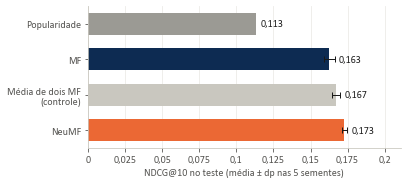

In [20]:
# NDCG@10 de teste dos tres modelos e do controle com dois MF (media e desvio-padrao nas sementes)
nd_teste = tabela[(tabela.conjunto == "teste") & (tabela.metrica == "ndcg")].set_index("modelo")
dois_mf = controles[controles.controle == "média de dois MF"].teste_ndcg
barras = [("Popularidade", nd_teste.media["pop"], 0.0, CORES["pop"]),
          ("MF", nd_teste.media["mf"], nd_teste.dp["mf"], CORES["mf"]),
          ("Média de dois MF\n(controle)", dois_mf.mean(), dois_mf.std(), CINZA_CLARO),
          ("NeuMF", nd_teste.media["neumf"], nd_teste.dp["neumf"], CORES["neumf"])]
fig, ax = plt.subplots(figsize=(5.6, 2.6))
for j, (nome, media, dp, cor) in enumerate(barras):
    y = len(barras) - 1 - j      # a primeira da lista fica em cima
    ax.barh(y, media, color=cor, height=0.62)
    if dp > 0:
        ax.errorbar(media, y, xerr=dp, color=TINTA, capsize=3, lw=1)
    ax.text(media + dp + 0.003, y, br(media, 3), va="center", color=TINTA)
ax.set_yticks(range(len(barras)))
ax.set_yticklabels([b[0] for b in barras][::-1])
ax.set_xlabel("NDCG@10 no teste (média ± dp nas %d sementes)" % len(SEMENTES))
ax.set_xlim(0, nd_teste.media.max() * 1.22)
ax.grid(axis="y", visible=False)
virgula(ax, "x")
mostra(fig, "resultados")

## 7. Conferências de sanidade

In [21]:
sanidade = []


def confere(nome, ok, detalhe=""):
    sanidade.append({"checagem": nome, "passou": bool(ok), "detalhe": detalhe})


sobreposicao = ((dados["treino"] & dados["val_todos"]) | (dados["treino"] & dados["teste_todos"])
                | (dados["val_todos"] & dados["teste_todos"]))
confere("conjuntos disjuntos", not sobreposicao.any())
# primeira e ultima data de cada usuario em cada conjunto
lim = tab.groupby(["u", "conjunto"]).ts.agg(["min", "max"]).unstack()
confere("treino antes da validação, que vem antes do teste (por usuário)",
        ((lim["max"]["treino"] <= lim["min"]["val"]) & (lim["max"]["val"] <= lim["min"]["teste"])).all())
tem_tudo = ((dados["treino"].sum(axis=1) > 0) & (dados["val"].sum(axis=1) > 0) & (dados["teste"].sum(axis=1) > 0))
confere("todo usuário tem treino, validação e teste", tem_tudo.all())
confere("popularidade bem melhor que ranking aleatório", nd_pop > 5 * nd_alea, "%.4f contra %.4f" % (nd_pop, nd_alea))
# mascara montada a parte (sem chamar proibidos), senao um erro em proibidos() passaria aqui tambem
nao_pode = dados["treino"] | dados["val_todos"] | ~dados["cand"][None, :]
erros, fora_intervalo = 0, 0
for tipo in ["mf", "neumf"]:
    for s in SEMENTES:
        m = aval_teste[tipo][s]
        erros += int(np.take_along_axis(nao_pode, m["top"], axis=1).sum())
        for nome in ["ndcg", "recall", "mrr"]:
            x = m[nome][np.isfinite(m[nome])]
            fora_intervalo += int(((x < 0) | (x > 1)).sum())
erros += int(np.take_along_axis(nao_pode, aval_pop["top"], axis=1).sum())
confere("nenhum filme de treino/validação ou fora do catálogo no top-10 de teste", erros == 0, "%d casos" % erros)
confere("métricas por usuário entre 0 e 1", fora_intervalo == 0, "%d valores fora" % fora_intervalo)
sanidade = pd.DataFrame(sanidade)
salva(sanidade, "sanidade")
sanidade

,checagem,passou,detalhe
0,conjuntos disjuntos,True,
1,"treino antes da validação, que vem antes do te...",True,
2,"todo usuário tem treino, validação e teste",True,
3,popularidade bem melhor que ranking aleatório,True,0.1133 contra 0.0147
4,nenhum filme de treino/validação ou fora do ca...,True,0 casos
5,métricas por usuário entre 0 e 1,True,0 valores fora


## 8. Vazamento de informação

Três experimentos medem o quanto o resultado fica otimista quando informação do futuro entra no treino:

1. **Ordem embaralhada.** O mesmo 70/10/20 por usuário, mas em ordem aleatória: o treino passa a ter avaliações
   feitas depois das do teste.
2. **Amostrador "esperto".** Sortear os negativos evitando os filmes que o usuário vai ver depois (na validação e
   no teste). Mesmo modelo e mesma semente, só muda o amostrador.
3. **Popularidade contada com o futuro.** Contar a popularidade com treino + validação + teste.

In [22]:
cont_treino = dados["treino"].sum(axis=0)


def grupos_popularidade(contagem):
    # populares / intermediarios / cauda = tercos da massa de interacoes do treino
    ordem = np.argsort(-contagem, kind="stable")
    ordem = ordem[contagem[ordem] > 0]
    acum = np.cumsum(contagem[ordem]) / contagem.sum()
    g = np.full(NI, "fora", dtype=object)
    g[ordem] = np.where(acum <= 1 / 3, "populares", np.where(acum <= 2 / 3, "intermediarios", "cauda"))
    return g


def composicao_teste(d, nome):
    # quao populares sao os filmes do teste, com a popularidade contada no treino do proprio split
    contagem = d["treino"].sum(axis=0)
    grupo = grupos_popularidade(contagem)
    ii = np.nonzero(d["teste"])[1]          # o filme de cada interacao de teste
    return {"split": nome, "pct_teste_populares": 100 * np.mean(grupo[ii] == "populares"),
            "popularidade_media_teste": contagem[ii].mean()}


grupo_item = grupos_popularidade(cont_treino)
splits_embaralhados = {}
embaralhado = []
composicao = [composicao_teste(dados, "temporal")]
for s in SEMENTES_EMBARALHADO:
    d_emb = separa(notas, embaralhado=True, semente=s)
    splits_embaralhados[s] = d_emb
    composicao.append(composicao_teste(d_emb, "embaralhado %d" % s))
    # mesmos hiperparametros escolhidos no split temporal; o pre-treino do NeuMF e refeito neste split
    p_mf_emb, _ = treina("mf", hp_mf, d_emb, s)
    p_g_emb, _ = treina("gmf", hp_gmf, d_emb, s)
    p_m_emb, _ = treina("mlp", hp_mlp, d_emb, s)
    p_n_emb, _ = treina("neumf", hp_neumf, d_emb, s, pesos_iniciais=junta_pretreino(p_g_emb, p_m_emb))
    S_emb = {"pop": escores_pop(d_emb["treino"]),
             "mf": escores("mf", p_mf_emb),
             "neumf": escores("neumf", p_n_emb)}
    for tipo, S in S_emb.items():
        ndcg_emb = np.nanmean(avalia(S, d_emb, "teste")["ndcg"])
        embaralhado.append({"modelo": tipo, "semente": s, "teste_ndcg": ndcg_emb})
    print("ordem embaralhada, repetição %d ok" % s)
embaralhado = pd.DataFrame(embaralhado)
composicao = pd.DataFrame(composicao)
salva(embaralhado, "embaralhado")
salva(composicao, "embaralhado_composicao")

comp_emb = []
for tipo in ["pop", "mf", "neumf"]:
    temporal = finais[finais.modelo == tipo].teste_ndcg.mean()
    e = embaralhado[embaralhado.modelo == tipo].teste_ndcg
    comp_emb.append({"modelo": tipo, "temporal": temporal, "embaralhado": e.mean(),
                     "embaralhado_dp": e.std(ddof=1) if len(e) > 1 else 0.0,
                     "inflacao_pct": 100 * (e.mean() / temporal - 1)})
comp_emb = pd.DataFrame(comp_emb)
salva(comp_emb, "embaralhado_vs_temporal")
display(composicao)
print("parte do teste nos filmes populares: %.1f%% no split temporal e %.1f%% na média dos embaralhados"
      % (composicao.pct_teste_populares.iloc[0], composicao.pct_teste_populares.iloc[1:].mean()))
comp_emb

ordem embaralhada, repetição 1 ok


ordem embaralhada, repetição 2 ok


ordem embaralhada, repetição 3 ok


,split,pct_teste_populares,popularidade_media_teste
0,temporal,17.5478,92.4675
1,embaralhado 1,32.9779,117.2042
2,embaralhado 2,32.9141,116.7664
3,embaralhado 3,32.5318,116.3486


parte do teste nos filmes populares: 17.5% no split temporal e 32.8% na média dos embaralhados


,modelo,temporal,embaralhado,embaralhado_dp,inflacao_pct
0,pop,0.1133,0.2245,0.0042,98.0771
1,mf,0.1626,0.3935,0.0105,142.0040
2,neumf,0.1727,0.4060,0.0060,135.0733


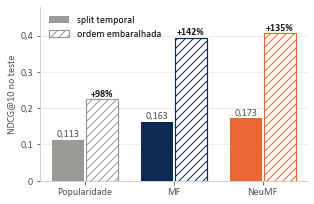

In [23]:
# NDCG@10 de teste no split temporal (barra cheia) e com a ordem embaralhada (barra hachurada)
fig, ax = plt.subplots(figsize=(4.8, 3.2))
x = np.arange(len(comp_emb))
cores = [CORES[t] for t in comp_emb.modelo]
ax.bar(x - 0.19, comp_emb.temporal, width=0.36, color=cores, label="split temporal")
ax.bar(x + 0.19, comp_emb.embaralhado, width=0.36, color="white", edgecolor=cores, hatch="///", lw=1.2,
       label="ordem embaralhada")
for j, r in enumerate(comp_emb.itertuples()):
    ax.text(j - 0.19, r.temporal + 0.008, br(r.temporal, 3), ha="center", color=TINTA2)
    ax.text(j + 0.19, r.embaralhado + 0.008, sinal(r.inflacao_pct, 0) + "%", ha="center", color=TINTA,
            fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([NOMES[t] for t in comp_emb.modelo])
ax.set_ylabel("NDCG@10 no teste")
ax.set_ylim(0, comp_emb.embaralhado.max() * 1.18)
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
virgula(ax, "y")
mostra(fig, "embaralhado")

In [24]:
# o MF "certo" e o proprio MF escolhido na busca (mesma configuracao, semente 0): nao precisa treinar de novo
p_certo = pesos_busca[i_mf]
# tudo o que o usuario avaliou em algum momento (treino, validacao e teste)
ja_viu = dados["treino"] | dados["val_todos"] | dados["teste_todos"]
# amostrador "esperto": tira do sorteio tambem os filmes que o usuario vai ver na validacao e no teste
p_vazado, info_vazado = treina("mf", hp_mf, dados, SEMENTE_BUSCA, visto=ja_viu)
nd_certo = np.nanmean(avalia(escores("mf", p_certo), dados, "teste")["ndcg"])
nd_vazado = np.nanmean(avalia(escores("mf", p_vazado), dados, "teste")["ndcg"])

# com o amostrador certo, que parte dos negativos sorteados cai num filme que o usuario vai ver depois?
treino_u = np.nonzero(dados["treino"])[0]
uu, jj = sorteia_negativos(treino_u, dados["treino"], cand_idx, hp_mf["neg"], np.random.default_rng(SEMENTE_BUSCA))
pct_colisao = 100 * (dados["val_todos"] | dados["teste_todos"])[uu, jj].mean()

# popularidade contada com o futuro
nd_pop_futuro = np.nanmean(avalia(escores_pop(ja_viu), dados, "teste")["ndcg"])

vazamento = []
for modelo, correto, vazado in zip(comp_emb.modelo, comp_emb.temporal, comp_emb.embaralhado):
    vazamento.append({"experimento": "ordem embaralhada", "modelo": modelo, "correto": correto,
                      "com_vazamento": vazado})
vazamento.append({"experimento": "amostrador que evita os filmes futuros", "modelo": "mf",
                  "correto": nd_certo, "com_vazamento": nd_vazado})
vazamento.append({"experimento": "popularidade contada com o futuro", "modelo": "pop",
                  "correto": nd_pop, "com_vazamento": nd_pop_futuro})
vazamento = pd.DataFrame(vazamento)
vazamento["inflacao_pct"] = 100 * (vazamento.com_vazamento / vazamento.correto - 1)
salva(vazamento, "vazamento")
print("negativos que caem em filmes futuros do usuário (amostrador certo): %.2f%%" % pct_colisao)
print("melhor época do MF: amostrador certo %d, vazado %d" % (busca[i_mf]["melhor_epoca"], info_vazado["melhor_epoca"]))
vazamento

negativos que caem em filmes futuros do usuário (amostrador certo): 4.43%
melhor época do MF: amostrador certo 14, vazado 59


,experimento,modelo,correto,com_vazamento,inflacao_pct
0,ordem embaralhada,pop,0.1133,0.2245,98.0771
1,ordem embaralhada,mf,0.1626,0.3935,142.0040
2,ordem embaralhada,neumf,0.1727,0.4060,135.0733
3,amostrador que evita os filmes futuros,mf,0.1586,0.4337,173.4058
4,popularidade contada com o futuro,pop,0.1133,0.1167,3.0000


Outras checagens de vazamento, que não precisam de treino: quanto do "futuro" global ainda entra no treino no split
temporal por usuário, o que aconteceria com um corte único no tempo, e filmes duplicados.

In [25]:
def pct_treino_depois(tabela):
    # para cada interacao de teste: que % das interacoes de treino (de todos os usuarios) e posterior a ela
    tr = np.sort(tabela[tabela.conjunto == "treino"].ts.values)
    te = tabela[tabela.conjunto == "teste"].ts.values
    depois = len(tr) - np.searchsorted(tr, te, side="right")
    return 100 * depois.mean() / len(tr)


checagens = {}
checagens["pct_treino_depois_temporal"] = pct_treino_depois(tab)
checagens["pct_treino_depois_embaralhado"] = np.mean(
    [pct_treino_depois(d["tabela"]) for d in splits_embaralhados.values()])

# corte unico no tempo (80% das avaliacoes antes da data, 20% depois): quem cai no teste tem historico?
ts = np.sort(notas.ts.values)
corte = ts[int(0.8 * len(ts))]
antes = notas[notas.ts < corte]
depois_corte = notas[notas.ts >= corte]
usuarios_teste = depois_corte.u.unique()
sem_historico = ~np.isin(usuarios_teste, antes.u.unique())
checagens["corte_global_data"] = str(pd.to_datetime(corte, unit="s").date())
checagens["corte_global_usuarios_no_teste"] = len(usuarios_teste)
checagens["corte_global_usuarios_sem_historico"] = int(sem_historico.sum())
checagens["corte_global_pct_sem_historico"] = 100 * sem_historico.mean()

# filmes duplicados: interacoes de teste cuja "copia" (mesmo titulo, outro id) esta no treino do mesmo usuario
copias = {}   # filme -> os outros ids com o mesmo titulo
for _, ids in duplicados.groupby("title").item_id:
    ids = [x - 1 for x in ids]
    for x in ids:
        copias[x] = [y for y in ids if y != x]
te = tab[tab.conjunto == "teste"]
n_copias = 0
for u, i in zip(te.u.values, te.i.values):
    for outro in copias.get(i, []):
        if dados["treino"][u, outro]:
            n_copias += 1
            break      # conta cada interacao uma vez so
checagens["teste_com_copia_no_treino"] = n_copias
checagens["pct_negativos_que_sao_filmes_futuros"] = pct_colisao
checagens["pct_avaliacoes_empatadas"] = 100 * empatado.mean()
checagens["avaliacoes_antes_do_lancamento"] = int(antes_lancamento.sum())
salva(pd.DataFrame({"medida": list(checagens), "valor": list(checagens.values())}), "vazamento_checagens")
pd.Series(checagens)

pct_treino_depois_temporal                 40.9149
pct_treino_depois_embaralhado              50.0099
corte_global_data                       1998-03-07
corte_global_usuarios_no_teste                 301
corte_global_usuarios_sem_historico            192
corte_global_pct_sem_historico             63.7874
teste_com_copia_no_treino                       48
pct_negativos_que_sao_filmes_futuros        4.4344
pct_avaliacoes_empatadas                    75.772
avaliacoes_antes_do_lancamento                 231
dtype: object

## 9. Calibração

Com entropia cruzada, $\sigma(z)$ deveria ser a probabilidade de o usuário ver o filme. Mas o modelo foi treinado
com $k$ negativos por positivo, então essa "probabilidade" se refere a uma mistura artificial (1 visto para $k$ não
vistos), e não ao ranking real do teste, em que há cerca de 68 filmes não vistos para cada filme que o usuário vai
ver. Medimos isso no teste em dois cenários:

- **na razão do treino**: cada filme relevante do teste com $k$ negativos sorteados entre filmes que o usuário
  nunca avaliou;
- **no catálogo inteiro**: todos os candidatos do ranking, com a proporção real de relevantes.

Reportamos a probabilidade média prevista dividida pela taxa real (1 = calibrado na média), o ECE (média,
ponderada pelo número de pares de cada faixa, da diferença absoluta entre a probabilidade prevista e a frequência
observada, em 10 faixas de probabilidade) e o Brier (erro quadrático médio entre $\sigma(z)$ e $y$). A correção de
prior $\sigma(z + \log(k_{treino}/k_{real}))$, em que $k_{real}$ é o número de candidatos não relevantes por
relevante no teste, ajusta a escala para a proporção real sem retreinar.

In [26]:
def sigmoide(z):
    return 1 / (1 + np.exp(-np.clip(z, -40, 40)))


def confiabilidade(p, y, n_faixas=10):
    # faixa 0 = [0; 0,1), ..., faixa 9 = [0,9; 1]; o minimum poe p = 1 na ultima faixa
    faixa = np.minimum((p * n_faixas).astype(int), n_faixas - 1)
    linhas = []
    for f in range(n_faixas):
        m = faixa == f
        if m.any():
            linhas.append({"faixa": f, "p_media": p[m].mean(), "freq_observada": y[m].mean(), "n": int(m.sum())})
    return linhas


def ece(p, y):
    # media, ponderada pelo tamanho da faixa, de |previsto - observado|
    total = 0.0
    for f in confiabilidade(p, y):
        total += f["n"] * abs(f["p_media"] - f["freq_observada"])
    return total / len(p)


# pares de teste: cada relevante + 8 negativos entre filmes que o usuario nunca avaliou (os mesmos pros dois modelos)
teste_u, teste_i = np.nonzero(dados["teste"])      # um par (usuario, filme) por relevante de teste
_, negs = sorteia_negativos(teste_u, ja_viu, cand_idx, 8, np.random.default_rng(SEMENTE_CALIBRACAO))
negs = negs.reshape(-1, 8)                          # linha j: os 8 negativos do relevante j

proib_teste = proibidos(dados, "teste")
calib, conf = [], []
for tipo, k in [("mf", hp_mf["neg"]), ("neumf", hp_neumf["neg"])]:
    for s in SEMENTES:
        S = S_final[tipo][s]
        # cenario 1: razao do treino (1 relevante para k negativos). S[teste_u[:, None], negs[:, :k]] e uma
        # matriz (relevantes x k) com os escores dos k negativos de cada relevante
        z = np.concatenate([S[teste_u, teste_i], S[teste_u[:, None], negs[:, :k]].ravel()])
        y = np.concatenate([np.ones(len(teste_u)), np.zeros(len(teste_u) * k)])
        p = sigmoide(z)
        # aqui k_real = k, entao a correcao de prior nao muda nada
        calib.append({"modelo": tipo, "semente": s, "cenario": "razão do treino", "k_treino": k, "k_real": k,
                      "p_media": p.mean(), "taxa_real": y.mean(), "ece": ece(p, y), "brier": np.mean((p - y) ** 2),
                      "p_media_corrigida": p.mean(), "ece_corrigido": ece(p, y)})
        if s == SEMENTES[0]:
            conf += [dict(modelo=tipo, cenario="razão do treino", **c) for c in confiabilidade(p, y)]
        # cenario 2: catalogo inteiro (todos os candidatos que o usuario ainda nao viu)
        z = S[~proib_teste]
        y = dados["teste"][~proib_teste].astype(float)
        k_real = (1 - y).sum() / y.sum()
        p = sigmoide(z)
        pc = sigmoide(z + np.log(k / k_real))   # correcao de prior
        calib.append({"modelo": tipo, "semente": s, "cenario": "catálogo inteiro", "k_treino": k, "k_real": k_real,
                      "p_media": p.mean(), "taxa_real": y.mean(), "ece": ece(p, y), "brier": np.mean((p - y) ** 2),
                      "p_media_corrigida": pc.mean(), "ece_corrigido": ece(pc, y)})
        if s == SEMENTES[0]:
            conf += [dict(modelo=tipo, cenario="catálogo inteiro", **c) for c in confiabilidade(p, y)]
            conf += [dict(modelo=tipo, cenario="catálogo inteiro, corrigido", **c) for c in confiabilidade(pc, y)]

calib = pd.DataFrame(calib)
calib_resumo = calib.groupby(["modelo", "cenario"], sort=False).mean(numeric_only=True).reset_index()
calib_resumo["razao_p_taxa"] = calib_resumo.p_media / calib_resumo.taxa_real
calib_resumo["razao_corrigida"] = calib_resumo.p_media_corrigida / calib_resumo.taxa_real
# referencia: o Brier de prever sempre a taxa real
calib_resumo["brier_constante"] = calib_resumo.taxa_real * (1 - calib_resumo.taxa_real)
salva(calib_resumo.drop(columns="semente"), "calibracao")
salva(pd.DataFrame(conf), "confiabilidade")
calib_resumo[["modelo", "cenario", "k_treino", "k_real", "p_media", "taxa_real", "razao_p_taxa", "razao_corrigida",
              "ece", "brier", "brier_constante"]]

,modelo,cenario,k_treino,k_real,p_media,taxa_real,razao_p_taxa,razao_corrigida,ece,brier,brier_constante
0,mf,razão do treino,8.0,8.0000,0.0565,0.1111,0.5084,0.5084,0.0613,0.0890,0.0988
1,mf,catálogo inteiro,8.0,68.3372,0.0435,0.0144,3.0173,0.5912,0.0291,0.0231,0.0142
2,neumf,razão do treino,8.0,8.0000,0.0627,0.1111,0.5645,0.5645,0.0581,0.0879,0.0988
3,neumf,catálogo inteiro,8.0,68.3372,0.0442,0.0144,3.0627,0.6472,0.0301,0.0250,0.0142


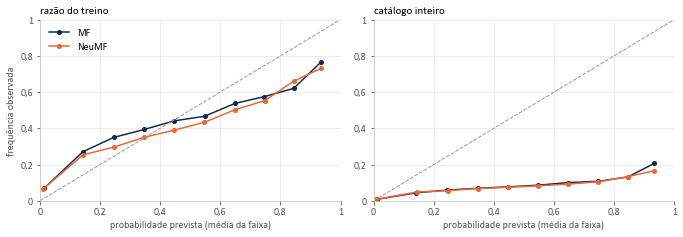

In [27]:
# diagrama de confiabilidade (semente 1): cada ponto e uma faixa de probabilidade prevista; a diagonal e o calibrado
conf_df = pd.DataFrame(conf)
fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.4))
for j, cenario in enumerate(["razão do treino", "catálogo inteiro"]):
    for tipo in ["mf", "neumf"]:
        c = conf_df[(conf_df.modelo == tipo) & (conf_df.cenario == cenario)]
        ax[j].plot(c.p_media, c.freq_observada, "o-", color=CORES[tipo], label=NOMES[tipo], ms=4)
    ax[j].plot([0, 1], [0, 1], "--", color=CINZA, lw=1)
    ax[j].set_xlim(0, 1)
    ax[j].set_ylim(0, 1)
    ax[j].set_title(cenario)
    ax[j].set_xlabel("probabilidade prevista (média da faixa)")
    virgula(ax[j])
ax[0].set_ylabel("frequência observada")
ax[0].legend(loc="upper left")
plt.tight_layout()
mostra(fig, "calibracao_confiabilidade")

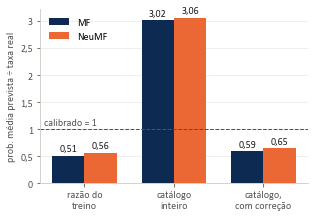

In [28]:
# escala das probabilidades: media prevista / taxa real (1 = certo na media) nos dois cenarios e com a correcao
cenarios = [("razão do treino", "razao_p_taxa", "razão do\ntreino"),
            ("catálogo inteiro", "razao_p_taxa", "catálogo\ninteiro"),
            ("catálogo inteiro", "razao_corrigida", "catálogo,\ncom correção")]
fig, ax = plt.subplots(figsize=(4.8, 3.2))
x = np.arange(len(cenarios))
for j, tipo in enumerate(["mf", "neumf"]):
    r = calib_resumo[calib_resumo.modelo == tipo].set_index("cenario")
    v = [r.loc[cenario, coluna] for cenario, coluna, _ in cenarios]
    ax.bar(x + (j - 0.5) * 0.36, v, width=0.36, color=CORES[tipo], label=NOMES[tipo])
    for xx, vv in zip(x, v):
        ax.text(xx + (j - 0.5) * 0.36, vv + 0.08, br(vv, 2), ha="center", color=TINTA)
ax.axhline(1, color=TINTA2, lw=1, ls="--")
ax.text(-0.45, 1.08, "calibrado = 1", color=TINTA2)
ax.set_xticks(x)
ax.set_xticklabels([rotulo for _, _, rotulo in cenarios])
ax.set_ylabel("prob. média prevista ÷ taxa real")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
virgula(ax, "y")
mostra(fig, "calibracao_escala")

## 10. Resíduos e diagnósticos por segmento

Resíduo = observado − previsto ($y - \sigma(z)$) nos pares de teste na razão do treino (os mesmos da calibração),
agrupado pela popularidade do filme e pela atividade do usuário. A tabela mostra também a razão previsto ÷
observado (1 = calibrado no grupo; abaixo de 1, o modelo prevê menos do que acontece). Depois comparamos NeuMF e
MF por grupo de usuários (quintis de atividade no treino, sexo e idade) e por grupo de filmes (populares,
intermediários e cauda, que são os terços da massa de interações do treino). Os intervalos vêm de bootstrap nos
usuários; como são muitos grupos, a comparação por grupo é exploratória.

In [29]:
n_treino = dados["treino"].sum(axis=1)
quintil = pd.qcut(n_treino, 5, labels=False) + 1
nome_quintil = {}
for q in range(1, 6):
    nome_quintil[q] = "Q%d (%d-%d)" % (q, n_treino[quintil == q].min(), n_treino[quintil == q].max())
# decil de popularidade dos filmes do catalogo. O rank(method="first") desempata pela ordem do item_id e deixa
# ~157 filmes em cada decil (sem ele, os empates de contagem fariam decis de tamanhos bem diferentes)
contagem_cand = pd.Series(cont_treino[cand_idx]).rank(method="first")
decil = np.full(NI, -1)
decil[cand_idx] = pd.qcut(contagem_cand, 10, labels=False).values + 1

residuos = []
rng = np.random.default_rng(0)
for tipo, k in [("mf", hp_mf["neg"]), ("neumf", hp_neumf["neg"])]:
    uu = np.concatenate([teste_u, np.repeat(teste_u, k)])
    jj = np.concatenate([teste_i, negs[:, :k].ravel()])
    y = np.concatenate([np.ones(len(teste_u)), np.zeros(len(teste_u) * k)])
    # previsto em cada par: media das sementes
    p = np.mean([sigmoide(S_final[tipo][s][uu, jj]) for s in SEMENTES], axis=0)
    for agrupamento, g in [("decil de popularidade do filme", decil[jj]), ("quintil de atividade", quintil[uu])]:
        for valor in np.unique(g):
            m = g == valor
            # IC do residuo medio por bootstrap nos usuarios (os pares de um mesmo usuario andam juntos)
            por_u = pd.DataFrame({"u": uu[m], "r": y[m] - p[m]}).groupby("u").r.agg(["sum", "size"])
            idx = rng.integers(0, len(por_u), (N_BOOT, len(por_u)))
            reamostras = por_u["sum"].values[idx].sum(axis=1) / por_u["size"].values[idx].sum(axis=1)
            residuos.append({"modelo": tipo, "agrupamento": agrupamento, "grupo": int(valor),
                             "y_medio": y[m].mean(), "p_medio": p[m].mean(), "residuo_medio": (y[m] - p[m]).mean(),
                             "ic_inf": np.quantile(reamostras, 0.025), "ic_sup": np.quantile(reamostras, 0.975),
                             "pares": int(m.sum())})
residuos = pd.DataFrame(residuos)
residuos["razao_p_y"] = residuos.p_medio / residuos.y_medio
salva(residuos, "residuos")
residuos.pivot_table(index=["agrupamento", "grupo"], columns="modelo", values=["residuo_medio", "razao_p_y"])

razao_p_y         residuo_medio        
modelo                                      mf   neumf            mf   neumf
agrupamento                    grupo                                        
decil de popularidade do filme 1        0.2789  0.1145        0.0075  0.0092
                               2        0.2407  0.1331        0.0138  0.0157
                               3        0.2053  0.1501        0.0270  0.0289
                               4        0.2372  0.2062        0.0372  0.0387
                               5        0.2792  0.2766        0.0547  0.0549
                               6        0.3312  0.3464        0.0694  0.0678
                               7        0.3905  0.4284        0.0835  0.0783
                               8        0.5138  0.5799        0.0802  0.0693
                               9        0.5936  0.6898        0.0908  0.0693
                               10       0.7315  0.8383        0.0923  0.0556
quintil de atividade           1        0.6821  0.6751        0.0353  0.0361
                               2        0.6561  0.6595        0.0382  0.0378
                               3        0.6296  0.6427        0.0412  0.0397
                               4        0.5701  0.6145        0.0478  0.0428
                               5        0.4097  0.4963        0.0656  0.0560

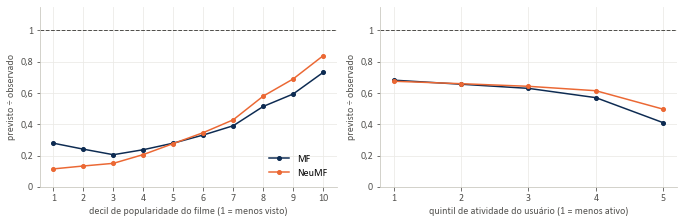

In [30]:
# previsto / observado por grupo: abaixo de 1, o modelo preve menos do que acontece no grupo
fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.2))
for tipo in ["mf", "neumf"]:
    r = residuos[residuos.modelo == tipo]
    por_decil = r[r.agrupamento == "decil de popularidade do filme"]
    por_quintil = r[r.agrupamento == "quintil de atividade"]
    ax[0].plot(por_decil.grupo, por_decil.razao_p_y, "o-", color=CORES[tipo], label=NOMES[tipo], ms=4)
    ax[1].plot(por_quintil.grupo, por_quintil.razao_p_y, "o-", color=CORES[tipo], label=NOMES[tipo], ms=4)
for a in ax:
    a.axhline(1, color=TINTA2, lw=1, ls="--")
    a.set_ylabel("previsto ÷ observado")
    a.set_ylim(0, max(1.15, 1.08 * residuos.razao_p_y.max()))
    virgula(a, "y")
ax[0].set_xlabel("decil de popularidade do filme (1 = menos visto)")
ax[0].set_xticks(range(1, 11))
ax[1].set_xlabel("quintil de atividade do usuário (1 = menos ativo)")
ax[1].set_xticks(range(1, 6))
ax[0].legend()
plt.tight_layout()
mostra(fig, "residuos")

In [31]:
def recall_grupo(top, rel, mascara):
    # recall@10 so com os relevantes do grupo de filmes (min(|R|, 10) no denominador)
    r = rel & mascara[None, :]
    acertos = np.take_along_axis(r, top, axis=1).sum(axis=1)
    n = r.sum(axis=1)
    return np.where(n > 0, acertos / np.maximum(np.minimum(n, K), 1), np.nan)


faixa_idade = pd.cut(usuarios.age, FAIXAS_IDADE, labels=NOMES_IDADE).astype(str).values   # u.user ja vem em ordem
sexo = usuarios.gender.values

# ndcg por usuario, media nas sementes
nd = {"pop": aval_pop["ndcg"], "mf": np.nanmean(matriz_usuarios("mf", "ndcg"), axis=0),
      "neumf": np.nanmean(matriz_usuarios("neumf", "ndcg"), axis=0)}

segmentos = []
rotulo_quintil = np.array([nome_quintil[q] for q in quintil])
for segmento, rotulos, ordem_grupos in [("atividade", rotulo_quintil, [nome_quintil[q] for q in range(1, 6)]),
                                        ("sexo", sexo, ["F", "M"]),
                                        ("idade", faixa_idade, NOMES_IDADE)]:
    for g in ordem_grupos:
        m = rotulos == g
        linha = {"segmento": segmento, "grupo": g, "metrica": "ndcg", "usuarios": int(m.sum())}
        for tipo in ["pop", "mf", "neumf"]:
            linha[tipo] = np.nanmean(nd[tipo][m])
        linha["neumf_vs_mf_pct"], linha["ic_inf"], linha["ic_sup"] = ic_relativo(nd["neumf"][m], nd["mf"][m])
        segmentos.append(linha)

rec = {}
for g in ["populares", "intermediarios", "cauda"]:
    mascara = grupo_item == g
    rec["pop"] = recall_grupo(aval_pop["top"], dados["teste"], mascara)
    for tipo in ["mf", "neumf"]:
        # quem nao tem relevante no grupo fica nan em todas as sementes, entao a media simples basta
        rec[tipo] = np.mean([recall_grupo(aval_teste[tipo][s]["top"], dados["teste"], mascara) for s in SEMENTES],
                            axis=0)
    linha = {"segmento": "popularidade do filme", "grupo": g, "metrica": "recall",
             "usuarios": int(np.isfinite(rec["mf"]).sum()), "filmes": int(mascara.sum())}
    for tipo in ["pop", "mf", "neumf"]:
        linha[tipo] = np.nanmean(rec[tipo])
    linha["neumf_vs_mf_pct"], linha["ic_inf"], linha["ic_sup"] = ic_relativo(rec["neumf"], rec["mf"])
    segmentos.append(linha)
segmentos = pd.DataFrame(segmentos)
salva(segmentos, "segmentos")

# a vantagem do NeuMF muda com a atividade? Q5 contra Q1, na escala absoluta (diferenca de NDCG) e na relativa
# (em pontos percentuais). As duas importam: o NDCG do Q5 e bem maior, entao um mesmo ganho relativo ja da uma
# diferenca absoluta maior
n5, m5 = nd["neumf"][quintil == 5], nd["mf"][quintil == 5]
n1, m1 = nd["neumf"][quintil == 1], nd["mf"][quintil == 1]
rng = np.random.default_rng(0)
boot_abs, boot_rel = [], []
for _ in range(N_BOOT):
    a = rng.integers(0, len(n5), len(n5))
    c = rng.integers(0, len(n1), len(n1))
    boot_abs.append((n5[a] - m5[a]).mean() - (n1[c] - m1[c]).mean())
    boot_rel.append(100 * (n5[a].mean() / m5[a].mean() - n1[c].mean() / m1[c].mean()))
interacao = {"dif_abs": (n5 - m5).mean() - (n1 - m1).mean(),
             "ic_abs_inf": np.quantile(boot_abs, 0.025), "ic_abs_sup": np.quantile(boot_abs, 0.975),
             "dif_rel_pp": 100 * (n5.mean() / m5.mean() - n1.mean() / m1.mean()),
             "ic_rel_inf": np.quantile(boot_rel, 0.025), "ic_rel_sup": np.quantile(boot_rel, 0.975)}
salva(pd.DataFrame([interacao]), "interacao_atividade")
display(pd.Series(interacao))
segmentos

dif_abs        0.0296
ic_abs_inf     0.0145
ic_abs_sup     0.0454
dif_rel_pp    11.2241
ic_rel_inf     2.7378
ic_rel_sup    20.1102
dtype: float64

,segmento,grupo,metrica,usuarios,pop,mf,neumf,neumf_vs_mf_pct,ic_inf,ic_sup,filmes
0,atividade,Q1 (14-20),ndcg,199,0.0675,0.1245,0.1291,3.7077,-1.8444,9.7374,NaN
1,atividade,Q2 (21-35),ndcg,193,0.0648,0.1285,0.1285,0.0458,-4.8809,4.8742,NaN
2,atividade,Q3 (36-65),ndcg,176,0.1016,0.1440,0.1506,4.6335,-0.6883,10.4793,NaN
3,atividade,Q4 (66-119),ndcg,186,0.1480,0.1890,0.1942,2.7821,-2.3177,7.9667,NaN
4,atividade,Q5 (120-515),ndcg,189,0.1879,0.2290,0.2632,14.9318,9.4764,20.7028,NaN
5,sexo,F,ndcg,273,0.0913,0.1543,0.1627,5.4715,0.9804,9.9455,NaN
6,sexo,M,ndcg,670,0.1223,0.1660,0.1768,6.5095,3.2089,9.7632,NaN
7,idade,até 24,ndcg,234,0.1284,0.1483,0.1575,6.1960,-0.2750,11.8950,NaN
8,idade,25-34,ndcg,310,0.1287,0.1634,0.1795,9.8482,5.2372,14.7857,NaN
9,idade,35-44,ndcg,194,0.0988,0.1677,0.1694,1.0318,-3.9194,6.1250,NaN


In [32]:
# quem fica sem nenhum acerto, e o quanto as listas puxam pro popular
vies = []
ii_teste = np.nonzero(dados["teste"])[1]
for tipo in ["pop", "mf", "neumf"]:
    tops = [aval_pop["top"]] if tipo == "pop" else [aval_teste[tipo][s]["top"] for s in SEMENTES]
    A = matriz_usuarios(tipo, "ndcg")                 # sementes x usuarios
    A = A[:, np.isfinite(A).all(axis=0)]
    recs = np.concatenate([t.ravel() for t in tops])
    vies.append({"modelo": tipo,
                 # % de usuarios sem nenhum acerto no top-10 em cada treino, media nas sementes
                 "pct_usuarios_sem_acerto": 100 * np.mean(A == 0),
                 # % que nao acerta em nenhuma das sementes (depende de quantas sementes ha)
                 "pct_sem_acerto_em_todas_sementes": 100 * np.mean((A == 0).all(axis=0)),
                 "pct_recomendacoes_populares": 100 * np.mean(grupo_item[recs] == "populares"),
                 "pct_teste_populares": 100 * np.mean(grupo_item[ii_teste] == "populares"),
                 "cobertura": np.mean([len(np.unique(t)) / NI for t in tops]),
                 "popularidade_media_recomendados": cont_treino[recs].mean(),
                 "popularidade_media_teste": cont_treino[ii_teste].mean()})
vies = pd.DataFrame(vies)
salva(vies, "vies_popularidade")
grupos_filmes = pd.DataFrame({"grupo": ["populares", "intermediarios", "cauda"],
                              "filmes": [int((grupo_item == g).sum()) for g in ["populares", "intermediarios", "cauda"]]})
salva(grupos_filmes, "grupos_filmes")
display(grupos_filmes)
vies

,grupo,filmes
0,populares,94
1,intermediarios,203
2,cauda,1277


,modelo,pct_usuarios_sem_acerto,pct_sem_acerto_em_todas_sementes,pct_recomendacoes_populares,pct_teste_populares,cobertura,popularidade_media_recomendados,popularidade_media_teste
0,pop,46.7656,46.7656,100.0000,17.5478,0.0440,365.9666,92.4675
1,mf,34.5281,20.4666,55.0159,17.5478,0.3754,205.5650,92.4675
2,neumf,34.2948,19.9364,60.4539,17.5478,0.3410,218.0128,92.4675


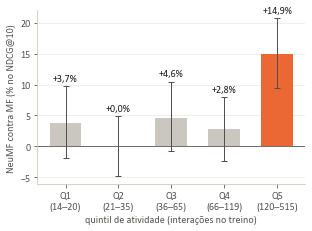

In [33]:
# vantagem do NeuMF sobre o MF por quintil de atividade, com o IC de 95% (laranja = intervalo acima de zero)
seg_at = segmentos[segmentos.segmento == "atividade"]
fig, ax = plt.subplots(figsize=(4.8, 3.2))
x = np.arange(len(seg_at))
cores = [LARANJA if inf > 0 else CINZA_CLARO for inf in seg_at.ic_inf]
ax.bar(x, seg_at.neumf_vs_mf_pct, color=cores, width=0.6)
erro = [seg_at.neumf_vs_mf_pct - seg_at.ic_inf, seg_at.ic_sup - seg_at.neumf_vs_mf_pct]
ax.errorbar(x, seg_at.neumf_vs_mf_pct, yerr=erro, fmt="none", color=TINTA2, capsize=3, lw=1)
ax.axhline(0, color=TINTA2, lw=0.8)
for xx, v, sup in zip(x, seg_at.neumf_vs_mf_pct, seg_at.ic_sup):
    ax.text(xx, sup + 0.8, sinal(v, 1) + "%", ha="center", color=TINTA)
ax.set_xticks(x)
ax.set_xticklabels([g.replace(" (", "\n(").replace("-", "–") for g in seg_at.grupo])
ax.set_xlabel("quintil de atividade (interações no treino)")
ax.set_ylabel("NeuMF contra MF (% no NDCG@10)")
ax.grid(axis="x", visible=False)
virgula(ax, "y")
mostra(fig, "segmentos_atividade")

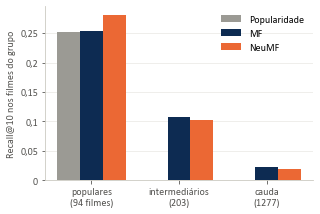

In [34]:
# Recall@10 so com os filmes de cada grupo de popularidade (tres barras lado a lado em cada grupo)
seg_pop = segmentos[segmentos.segmento == "popularidade do filme"]
fig, ax = plt.subplots(figsize=(4.8, 3.2))
for j, tipo in enumerate(["pop", "mf", "neumf"]):
    ax.bar(np.arange(3) + (j - 1) * 0.26, seg_pop[tipo], width=0.26, color=CORES[tipo], label=NOMES[tipo])
n_filmes = seg_pop.filmes.astype(int).tolist()
ax.set_xticks(range(3))
ax.set_xticklabels(["populares\n(%d filmes)" % n_filmes[0], "intermediários\n(%d)" % n_filmes[1],
                    "cauda\n(%d)" % n_filmes[2]])
ax.set_ylabel("Recall@10 nos filmes do grupo")
ax.legend()
ax.grid(axis="x", visible=False)
virgula(ax, "y")
mostra(fig, "segmentos_popularidade")

## 11. Custo computacional

Tempos medidos neste notebook, numa thread só. O custo do NeuMF inclui o treino do GMF e do MLP de que ele
depende (na busca e nas 5 sementes); o "s por época" dele é só o do ajuste fino. Como cada época tem $1 + k$
exemplos para cada positivo do treino (ele e os seus $k$ negativos), a tabela mostra também os exemplos por época.
A inferência é o tempo de calcular os escores de todos os pares e montar o top-10 dos 943 usuários.

In [35]:
def nome_cpu():
    # no Windows o nome comercial do processador fica no registro; no Linux, em /proc/cpuinfo
    try:
        import winreg
        chave = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
        return winreg.QueryValueEx(chave, "ProcessorNameString")[0].strip()
    except Exception:
        pass
    try:
        with open("/proc/cpuinfo") as f:
            for linha in f:
                if linha.startswith("model name"):
                    return linha.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor()


def tempo_inferencia(funcao, repeticoes=3):
    tempos = []
    for _ in range(repeticoes):
        t0 = time.perf_counter()
        S = funcao()
        np.argsort(-np.where(proib_teste, -np.inf, S), axis=1, kind="stable")[:, :K]
        tempos.append(time.perf_counter() - t0)
    return min(tempos)   # o menor dos 3 tempos, que sofre menos com outros programas rodando


busca_min = tab_busca.groupby("modelo").minutos.sum()
pre = pd.DataFrame(tempo_pretreino)
f_mf = finais[finais.modelo == "mf"]
f_n = finais[finais.modelo == "neumf"]
n_pos = int(dados["treino"].sum())
custo = pd.DataFrame([
    {"modelo": "pop", "parametros": NI, "k": np.nan, "s_por_epoca": 0.0, "busca_min": 0.0, "sementes_min": 0.0,
     "inferencia_s": tempo_inferencia(lambda: escores_pop(dados["treino"]))},
    {"modelo": "mf", "parametros": int(f_mf.parametros.iloc[0]), "k": hp_mf["neg"],
     "s_por_epoca": f_mf.s_por_epoca.mean(), "busca_min": busca_min["mf"], "sementes_min": f_mf.minutos.sum(),
     "inferencia_s": tempo_inferencia(lambda: escores("mf", p_mf_final))},
    {"modelo": "neumf", "parametros": int(f_n.parametros.iloc[0]), "k": hp_neumf["neg"],
     "s_por_epoca": f_n.s_por_epoca.mean(),
     "busca_min": busca_min["gmf"] + busca_min["mlp"] + busca_min["neumf"],
     "sementes_min": f_n.minutos.sum() + (pre.gmf_s.sum() + pre.mlp_s.sum()) / 60,
     "inferencia_s": tempo_inferencia(lambda: escores("neumf", p_neumf_final))},
])
custo["exemplos_por_epoca"] = (1 + custo.k) * n_pos
custo["total_min"] = custo.busca_min + custo.sementes_min
custo["memoria_parametros_mb"] = custo.parametros * 4 / 2 ** 20      # float32
salva(custo, "custo")

try:
    import psutil
    ram = round(psutil.virtual_memory().total / 2 ** 30, 1)
    nucleos = psutil.cpu_count(logical=False)
    mem = psutil.Process().memory_info()
    pico = getattr(mem, "peak_wset", mem.rss) / 2 ** 20   # no Windows da pra ler o pico; nos outros, o uso atual
except ImportError:
    ram, nucleos, pico = np.nan, os.cpu_count(), np.nan
sistema = platform.platform()
# o Python 3.10 ainda chama o Windows 11 (build 22000 em diante) de "Windows-10"
if platform.system() == "Windows" and int(platform.version().split(".")[-1]) >= 22000:
    sistema = sistema.replace("Windows-10", "Windows-11")
hardware = {"sistema": sistema, "processador": nome_cpu(), "nucleos_fisicos": nucleos,
            "ram_gb": ram, "python": platform.python_version(), "pytorch": torch.__version__,
            "threads_pytorch": torch.get_num_threads(), "memoria_processo_mb": pico}
salva(pd.DataFrame({"item": list(hardware), "valor": list(hardware.values())}), "hardware")
display(pd.Series(hardware))

por_modelo = custo.set_index("modelo")
# o pre-treino e o GMF e o MLP, tanto na busca quanto nas sementes
pretreino_min = busca_min["gmf"] + busca_min["mlp"] + (pre.gmf_s.sum() + pre.mlp_s.sum()) / 60
print("NeuMF contra MF: %.1f vezes o tempo de treino e %.0f vezes o tempo de inferência"
      % (por_modelo.total_min["neumf"] / por_modelo.total_min["mf"],
         por_modelo.inferencia_s["neumf"] / por_modelo.inferencia_s["mf"]))
print("pré-treino: %.0f%% do tempo de treino do NeuMF" % (100 * pretreino_min / por_modelo.total_min["neumf"]))
custo

sistema                                     Windows-11-10.0.26200-SP0
processador            11th Gen Intel(R) Core(TM) i7-1165G7 @ 2.80GHz
nucleos_fisicos                                                     4
ram_gb                                                           15.7
python                                                         3.10.5
pytorch                                                    2.14.0+cpu
threads_pytorch                                                     1
memoria_processo_mb                                         1006.0703
dtype: object

NeuMF contra MF: 2.8 vezes o tempo de treino e 7 vezes o tempo de inferência
pré-treino: 83% do tempo de treino do NeuMF


,modelo,parametros,k,s_por_epoca,busca_min,sementes_min,inferencia_s,exemplos_por_epoca,total_min,memoria_parametros_mb
0,pop,1682,NaN,0.0000,0.0000,0.0000,0.0490,NaN,0.0000,0.0064
1,mf,170626,8.0,1.4165,5.2050,2.6804,0.0633,626175.0,7.8854,0.6509
2,neumf,258849,8.0,2.6473,13.9246,8.0928,0.4558,626175.0,22.0174,0.9874


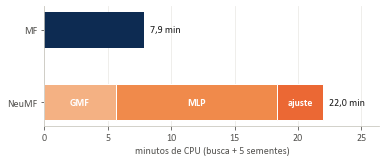

In [36]:
# minutos de CPU para chegar a cada modelo (busca + sementes); no NeuMF, separados por etapa
partes = [("GMF", busca_min["gmf"] + pre.gmf_s.sum() / 60, "#f4b183"),
          ("MLP", busca_min["mlp"] + pre.mlp_s.sum() / 60, "#f08a4b"),
          ("ajuste", busca_min["neumf"] + f_n.minutos.sum(), LARANJA)]
total_mf = por_modelo.total_min["mf"]
total_neumf = por_modelo.total_min["neumf"]
fig, ax = plt.subplots(figsize=(6.0, 2.2))
ax.barh(1, total_mf, color=AZUL, height=0.5)
esquerda = 0
for nome, minutos, cor in partes:
    ax.barh(0, minutos, left=esquerda, color=cor, height=0.5, edgecolor="white")
    if minutos > 0.1 * total_neumf:    # so escreve o nome se a fatia couber
        ax.text(esquerda + minutos / 2, 0, nome, ha="center", va="center", color="white", fontweight="bold")
    esquerda += minutos
ax.text(total_mf + 0.02 * total_neumf, 1, "%s min" % br(total_mf, 1), va="center", color=TINTA)
ax.text(1.02 * total_neumf, 0, "%s min" % br(total_neumf, 1), va="center", color=TINTA)
ax.set_yticks([1, 0])
ax.set_yticklabels(["MF", "NeuMF"])
ax.set_xlabel("minutos de CPU (busca + %d sementes)" % len(SEMENTES))
ax.set_xlim(0, 1.2 * total_neumf)
ax.grid(axis="y", visible=False)
virgula(ax, "x")
mostra(fig, "custo")

In [37]:
t_total = (time.time() - t_inicio) / 60
salva(pd.DataFrame([{"minutos": t_total, "rapido": RAPIDO}]), "tempo_notebook")
print("notebook inteiro: %.1f minutos" % t_total)
print("tabela de resultados (item 3):", EXCEL)
print("outras tabelas e figuras em", SAIDA)

notebook inteiro: 37.6 minutos
tabela de resultados (item 3): .\3_tabela_de_resultados.xlsx
outras tabelas e figuras em suporte\resultados
